# NHL: предсказать успешность команды в следующем сезоне

**Тестовое задание • 100 баллов**

Вы аналитик, которому после окончания сезона нужно оценить перспективы команды
на следующий год. Соберите таблицу с учебного сайта
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/),
изучите данные и постройте модель классификации.
В работе оцениваются корректность исследования и обоснованность решений.

Ориентир времени: 6-10 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами и исходный `data/hockey_raw.csv` разместите на платформе githib.com.
Укажите имя, дату и использованные источники и инструменты в README.

## Что предсказывает модель

Одна строка признаков описывает команду в сезоне `t`.
`target=1`, если доля побед той же команды в сезоне `t+1` строго выше медианной
доли побед всех команд в сезоне `t+1`. В остальных случаях `target=0`.

Медиану считайте по полной исходной таблице будущего года до отбора пар.
В пары включайте одинаковые названия команды с разницей меток сезонов ровно в один год.
Строки без пары исключайте и учитывайте в описании данных.
Будущий `win_rate` и будущая медиана используются для построения target и анализа
готовых прогнозов. Признаки модели должны быть известны после сезона `t`.

## Схема проверки

Делите данные по году целевого сезона:

| Часть | target_year | Назначение |
|---|---|---|
| train | не позднее 2005 | Подготовка данных и обучение |
| validation | 2006-2008 | Сравнение вариантов и выбор решения |
| test | 2009-2011 | Одна итоговая оценка выбранного решения |

Основная метрика: ROC-AUC по вероятности класса 1.
На итоговом этапе также используйте F1 и accuracy при пороге 0.5.
Финальный test используйте после выбора решения на validation.

## Как оценивается работа

| Область | Баллы |
|---|---:|
| Сбор и понимание данных | 15 |
| Построение задачи и корректность проверки | 20 |
| Исследовательский анализ | 20 |
| Модели и эксперименты | 25 |
| Итоговая оценка и анализ ошибок | 15 |
| Ясность и воспроизводимость | 5 |
| **Всего** | **100** |

Ниже перечислены обязательные этапы работы. Внутри них вы самостоятельно выбираете
исследовательские вопросы, графики, признаки, обработку данных, эксперимент и способ
разбора ошибок. Оценивается качество решений, а не совпадение с эталонным маршрутом.
Сложность метода сама по себе не даёт преимущества. Корректный эксперимент может
получить полный балл и в случае отсутствия улучшения.

## Требования к сбору

Итоговая исходная таблица должна иметь столбцы `team`, `year`, `wins`, `losses`,
`ot_losses`, `win_rate`, `goals_for`, `goals_against`, `goal_diff`.
Самостоятельно исследуйте страницу и определите способ получения всей таблицы.

**Автор:** Арасланов Тимур  
**Дата:** 13 октября 2026 г.  
**Использованные источники и инструменты:** Сайт Scrape This Site — Hockey Teams: https://www.scrapethissite.com/pages/forms/, статья The New York Times о правилах овертаймов в NHL:
https://www.nytimes.com/2008/02/17/sports/hockey/17score.html. Среда: Python 3.13, Google Colab. Библиотеки Python: pandas, numpy, requests, matplotlib, scipy, scikit-learn.

In [1]:
import os
import re
import time
from datetime import datetime
from io import StringIO

import pandas as pd
import requests
import matplotlib.pyplot as plt
import numpy as np


## Раздел 1. Сбор и понимание данных: 15 баллов

### 1.1. Соберите и сохраните данные

Соберите все страницы сайта в одну таблицу с указанными девятью столбцами.
Сохраните исходную выгрузку в `data/hockey_raw.csv`. Укажите URL и дату сбора,
число обработанных страниц и число строк. Покажите, как проверили,
что сбор не ограничился первой страницей и при повторном анализе можно читать CSV.

In [2]:
BASE_URL = "https://www.scrapethissite.com/pages/forms/"
first_page = requests.get(BASE_URL, params={"page_num": 1})
first_page.raise_for_status()
n_pages = max(int(n) for n in re.findall(r"page_num=(\d+)", first_page.text))
print("Количество страниц:", n_pages)

Количество страниц: 24


In [3]:
COLUMNS = ["team", "year", "wins", "losses", "ot_losses",
           "win_rate", "goals_for", "goals_against", "goal_diff"]

parts = []
for page in range(1, n_pages + 1):
    r = requests.get(BASE_URL, params={"page_num": page})
    table = pd.read_html(StringIO(r.text))[0]
    if page == 1:
        print("Исходные заголовки сайта:", list(table.columns))
    table.columns = COLUMNS
    parts.append(table)

rows_per_page = [len(p) for p in parts]
df = pd.concat(parts, ignore_index=True)
collected_at = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

Исходные заголовки сайта: ['Team Name', 'Year', 'Wins', 'Losses', 'OT Losses', 'Win %', 'Goals For (GF)', 'Goals Against (GA)', '+ / -']


In [4]:
os.makedirs("data", exist_ok=True)
df.to_csv("data/hockey_raw.csv", index=False)

print("URL:", BASE_URL)
print("Дата и время сбора:", collected_at)
print("Обработано страниц:", n_pages)
print("Строк:", len(df), "столбцов:", df.shape[1])
df.head()

URL: https://www.scrapethissite.com/pages/forms/
Дата и время сбора: 2026-10-13 16:46:36
Обработано страниц: 24
Строк: 582 столбцов: 9


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


In [5]:
print("Строк на каждой странице:", rows_per_page)
print("Сумма по страницам равна числу строк в таблице:", sum(rows_per_page) == len(df))
df.tail()

Строк на каждой странице: [25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 7]
Сумма по страницам равна числу строк в таблице: True


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
577,Tampa Bay Lightning,2011,38,36,8.0,0.463,235,281,-46
578,Toronto Maple Leafs,2011,35,37,10.0,0.427,231,264,-33
579,Vancouver Canucks,2011,51,22,9.0,0.622,249,198,51
580,Washington Capitals,2011,42,32,8.0,0.512,222,230,-8
581,Winnipeg Jets,2011,37,35,10.0,0.451,225,246,-21


In [6]:
df_check = pd.read_csv("data/hockey_raw.csv")

pd.testing.assert_frame_equal(df, df_check)
print("CSV читается и совпадает с собранной таблицей")
df_check.info()

CSV читается и совпадает с собранной таблицей
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   team           582 non-null    object 
 1   year           582 non-null    int64  
 2   wins           582 non-null    int64  
 3   losses         582 non-null    int64  
 4   ot_losses      358 non-null    float64
 5   win_rate       582 non-null    float64
 6   goals_for      582 non-null    int64  
 7   goals_against  582 non-null    int64  
 8   goal_diff      582 non-null    int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 41.1+ KB


**Ответ 1.1:**

Были собраны данные с 24 страниц с 9-ю правильными столбцами. После объединения получилась таблица с 582 строками. Количество строк на каждой из страниц одинаково (25), кроме последней (7), что свидетельствует о правильной работе с пагинацией. Сумма строк по страницам совпала с числом строк итоговой таблицы.Первые и последние 5 строк таблицы выглядят достоверно. Таблица сохранена в файл hockey_raw.csv и успешна прочитана, совпав с исходной - не вызвав ошибки через .testing.assert_frame_equal().


### 1.2. Проверьте качество таблицы

Изучите типы, пропуски и уникальность пары команда-год.
Добавьте не менее двух проверок согласованности, которые считаете важными
для последующего анализа. Покажите найденные особенности и обоснуйте
решения по их обработке. Сами проверки и способ представления результата выберите самостоятельно.

In [7]:
df = pd.read_csv("data/hockey_raw.csv")

print("Размер:", df.shape)
print("\nТипы столбцов:")
print(df.dtypes)
print("\nПропуски по столбцам:")
print(df.isna().sum())
print("\nПолных дубликатов строк:", df.duplicated().sum())
print("Повторов пары команда-год:", df.duplicated(["team", "year"]).sum())
df.describe()

Размер: (582, 9)

Типы столбцов:
team              object
year               int64
wins               int64
losses             int64
ot_losses        float64
win_rate         float64
goals_for          int64
goals_against      int64
goal_diff          int64
dtype: object

Пропуски по столбцам:
team               0
year               0
wins               0
losses             0
ot_losses        224
win_rate           0
goals_for          0
goals_against      0
goal_diff          0
dtype: int64

Полных дубликатов строк: 0
Повторов пары команда-год: 0


,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
count,582.000000,582.000000,582.000000,358.000000,582.000000,582.000000,582.000000,582.000000
mean,2000.907216,36.943299,32.353952,7.460894,0.458519,234.063574,234.063574,0.000000
std,6.330674,8.926081,8.411439,3.610191,0.102237,40.548915,42.510718,45.277458
min,1990.000000,9.000000,11.000000,0.000000,0.119000,115.000000,115.000000,-196.000000
25%,1996.000000,31.000000,27.000000,5.000000,0.390000,211.000000,207.000000,-27.000000
50%,2001.000000,38.000000,31.000000,7.000000,0.463000,231.000000,232.500000,4.000000
75%,2007.000000,43.000000,37.000000,10.000000,0.534000,254.000000,258.750000,31.000000
max,2011.000000,62.000000,71.000000,18.000000,0.756000,369.000000,414.000000,144.000000


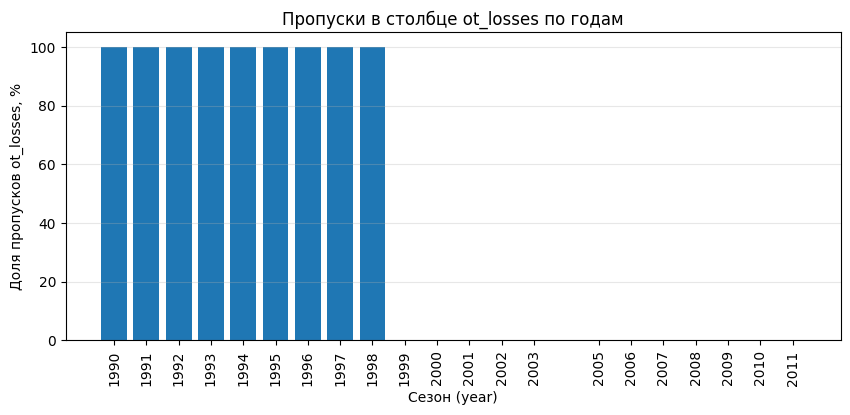

Годы, где ot_losses пуст у всех команд: [1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998]
Годы с частичными пропусками: []
Годы, где ot_losses заполнен у всех команд: [1999, 2000, 2001, 2002, 2003, 2005, 2006, 2007, 2008, 2009, 2010, 2011]
Нулевых значений ot_losses (настоящий 0, не пропуск): 2


In [8]:
import matplotlib.pyplot as plt

share_missing = df.groupby("year")["ot_losses"].apply(lambda s: s.isna().mean())
years = share_missing.index.astype(int)

plt.figure(figsize=(10, 4))
plt.bar(years, share_missing.values * 100)

plt.xlabel("Сезон (year)")
plt.ylabel("Доля пропусков ot_losses, %")
plt.title("Пропуски в столбце ot_losses по годам")
plt.xticks(years, rotation=90)
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)


plt.show()

print("Годы, где ot_losses пуст у всех команд:", list(share_missing[share_missing == 1].index))
print("Годы с частичными пропусками:", list(share_missing[(share_missing > 0) & (share_missing < 1)].index))
print("Годы, где ot_losses заполнен у всех команд:", list(share_missing[share_missing == 0].index))
print("Нулевых значений ot_losses (настоящий 0, не пропуск):", (df["ot_losses"] == 0).sum())

In [9]:
mismatch = df[df["goal_diff"] != df["goals_for"] - df["goals_against"]]
print("Расхождений goal_diff:", len(mismatch))

chk = df.copy()
chk["games"] = (chk["wins"] / chk["win_rate"]).round()
chk["other"] = chk["games"] - chk["wins"] - chk["losses"] - chk["ot_losses"].fillna(0)

print("\nВосстановленное число матчей (games = wins / win_rate) и остаток (other = games - wins - losses - ot_losses) по годам:")
print(chk.groupby("year")[["games", "other"]].agg(["min", "max"]).to_string())

print("\nwin_rate вне [0, 1]:", (~df["win_rate"].between(0, 1)).sum())

print("\nНазваний команд с лишними пробелами:", (df["team"] != df["team"].str.strip()).sum())

Расхождений goal_diff: 0

Восстановленное число матчей (games = wins / win_rate) и остаток (other = games - wins - losses - ot_losses) по годам:
     games       other      
       min   max   min   max
year                        
1990  80.0  80.0   6.0  19.0
1991  80.0  80.0   5.0  15.0
1992  84.0  84.0   2.0  12.0
1993  84.0  84.0   3.0  17.0
1994  48.0  48.0   3.0  12.0
1995  82.0  82.0   4.0  18.0
1996  82.0  82.0   7.0  19.0
1997  82.0  82.0   8.0  18.0
1998  82.0  82.0   5.0  19.0
1999  82.0  82.0   6.0  19.0
2000  82.0  82.0   5.0  17.0
2001  82.0  82.0   4.0  16.0
2002  82.0  82.0   6.0  16.0
2003  82.0  82.0   7.0  20.0
2005  82.0  82.0   0.0   0.0
2006  82.0  82.0   0.0   0.0
2007  82.0  82.0   0.0   0.0
2008  82.0  82.0   0.0   0.0
2009  82.0  82.0   0.0   0.0
2010  82.0  82.0   0.0   0.0
2011  82.0  82.0   0.0   0.0

win_rate вне [0, 1]: 0

Названий команд с лишними пробелами: 0


In [10]:
print("Строк (команд) по годам:")
print(df.groupby("year").size().to_string())

years_present = set(df["year"])
all_years = range(df["year"].min(), df["year"].max() + 1)
print("\nГоды без данных внутри периода:", [y for y in all_years if y not in years_present])


Строк (команд) по годам:
year
1990    21
1991    22
1992    24
1993    26
1994    26
1995    26
1996    26
1997    26
1998    27
1999    28
2000    30
2001    30
2002    30
2003    30
2005    30
2006    30
2007    30
2008    30
2009    30
2010    30
2011    30

Годы без данных внутри периода: [2004]


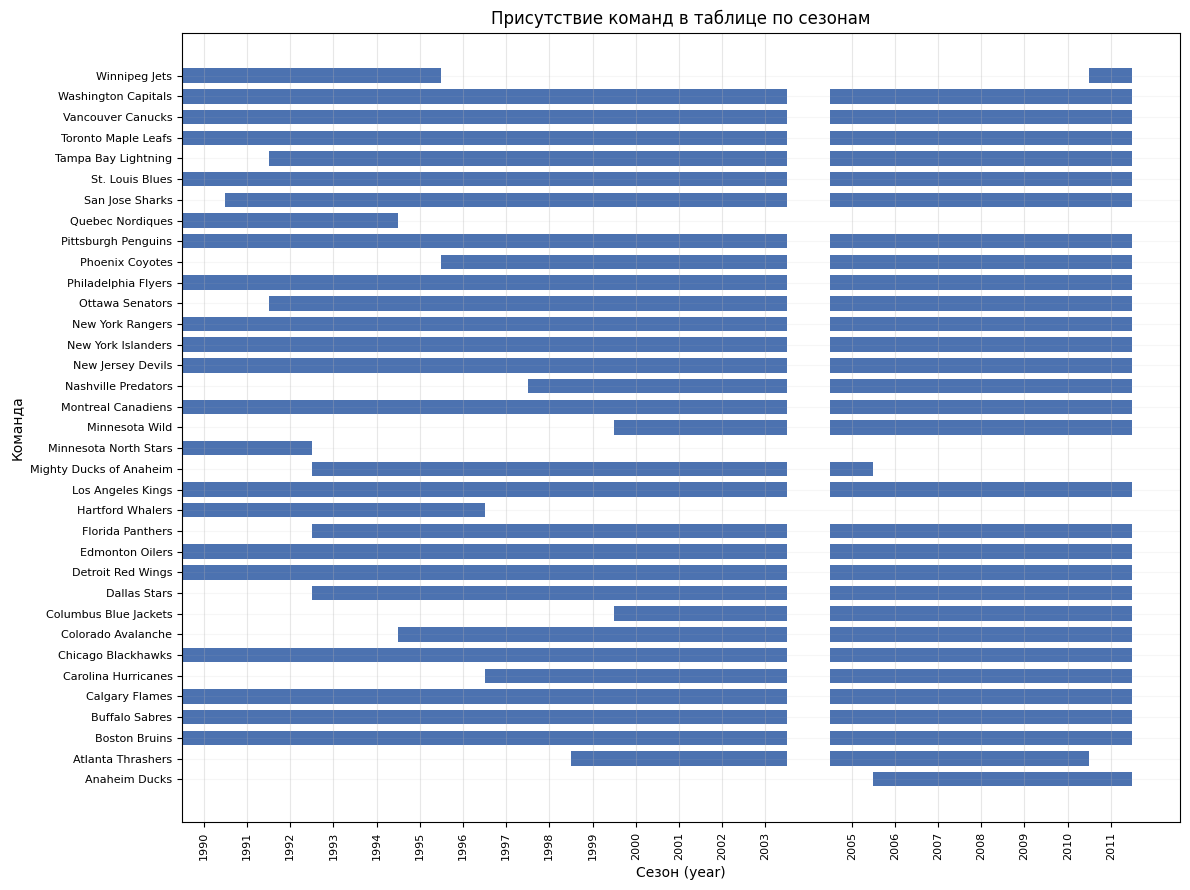

In [11]:
import matplotlib.pyplot as plt

teams = sorted(df["team"].unique())
teams_idx = {t: i for i, t in enumerate(teams)}

played = (
    df[["team", "year"]]
    .drop_duplicates()
    .sort_values(["team", "year"])
)

years = sorted(df["year"].unique())

fig, ax = plt.subplots(figsize=(12, 9))

for team, group in played.groupby("team"):
    y = teams_idx[team]
    team_years = sorted(group["year"].unique())

    start = prev = team_years[0]

    for year in team_years[1:]:
        if year == prev + 1:
            prev = year
        else:
            ax.barh(
                y=y,
                width=prev - start + 1,
                left=start - 0.5,
                height=0.7,
                color="#4C72B0"
            )

            start = prev = year

    ax.barh(
        y=y,
        width=prev - start + 1,
        left=start - 0.5,
        height=0.7,
        color="#4C72B0"
    )

ax.set_yticks(range(len(teams)))
ax.set_yticklabels(teams, fontsize=8)

ax.set_xticks(years)
ax.set_xticklabels(years, rotation=90, fontsize=8)

ax.set_xlabel("Сезон (year)")
ax.set_ylabel("Команда")
ax.set_title("Присутствие команд в таблице по сезонам")

ax.grid(axis="x", alpha=0.3)
ax.grid(axis="y", alpha=0.1)

plt.tight_layout()
plt.show()

**Ответ 1.2:**

Типы данных столбцов были определены парсером правильно. Пропуски (224) присутствуют только в столбце ot_losses. Причём пропуски ot_losses присутствуют во всех записях до 1998 года включительно, и их полностью нет начиная с 1999, что объясняется изменением правил игр (https://www.nytimes.com/2008/02/17/sports/hockey/17score.html).

Нет дубликатов строк и пар команда-год, что указывает на корректность сформированной таблицы. Данные таблицы .describe() показывают разумные значения: значения в разумных промежутках, отрицательные значения появляются только в столбце goal_diff. goal_diff во всех строках показала непротиворечивость с goals_for и goals_against. Подсчёт команд с максимальным и минимальным числом игр по годам показал, что все команды в каждом сезоне играли одинаковое число игр, но в разные сезоны было сыграно разное число игр (встречается 48, 80, 82 и 84 матча).

Подсчёт "других" результатов игр (other) через games - wins - losses - ot_losses дал нулевые значения с 2005 года, до этого имея положительные значения, что объясняется отменой ничьих (https://www.nytimes.com/2008/02/17/sports/hockey/17score.html).

win_rate оказался в нужном пределе [0, 1]. Названий команд с лишними пробелами не обнаружено. В каждом году участвовало в пределах 21-30 команд. Год пропуска без данных: 2004. За рассмотренный период 1990-2011 появлялись новые команды, некоторые завершали игру до 2011 года. Только одна команда (Winnipeg Jets) брала перерыв и затем возвращалась (не считая 2004 года, когда все команды не играли).

## Раздел 2. Построение задачи и корректность проверки: 20 баллов

### 2.1. Постройте target

Соедините строку команды в сезоне `t` с той же командой ровно в сезоне `t+1`
и постройте target по определению задания. Покажите число полученных пар,
число и годы исключённых строк, а также число случаев равенства будущей медиане.
Проверьте расчёт вручную минимум на двух содержательно разных примерах.

In [12]:
df = pd.read_csv("data/hockey_raw.csv")
EPS = 1e-9

season_median = df.groupby("year")["win_rate"].median()

future = (df[["team", "year", "win_rate"]]
          .rename(columns={"year": "target_year", "win_rate": "next_win_rate"}))
future["year"] = future["target_year"] - 1

merged = df.merge(future, on=["team", "year"], how="left",
                  validate="one_to_one", indicator=True)
has_pair = merged["_merge"] == "both"

pairs = merged[has_pair].drop(columns="_merge").copy()
pairs["target_year"] = pairs["target_year"].astype(int)
pairs["next_median_win_rate"] = pairs["target_year"].map(season_median)
pairs["target"] = (pairs["next_win_rate"] > pairs["next_median_win_rate"] + EPS).astype(int)
pairs["is_tie"] = np.isclose(pairs["next_win_rate"], pairs["next_median_win_rate"],
                             atol=EPS, rtol=0)

feature_cols_raw = ["wins", "losses", "ot_losses", "win_rate",
                    "goals_for", "goals_against", "goal_diff"]
pairs = pairs[["team", "year", "target_year"] + feature_cols_raw +
              ["next_win_rate", "next_median_win_rate", "target", "is_tie"]
              ].reset_index(drop=True)

print("Строк в исходной таблице:", len(df))
print("Пар t -> t+1:", len(pairs))
print("У всех пар разница сезонов ровно 1:", bool(((pairs["target_year"] - pairs["year"]) == 1).all()))
print("Повторов (team, year) среди пар:", int(pairs.duplicated(["team", "year"]).sum()))
print("Доля target=1 среди всех пар: %.3f" % pairs["target"].mean())
print("Случаев равенства будущей медиане (target=0 из-за строгого >):", int(pairs["is_tie"].sum()))
pairs.head()

Строк в исходной таблице: 582
Пар t -> t+1: 516
У всех пар разница сезонов ровно 1: True
Повторов (team, year) среди пар: 0
Доля target=1 среди всех пар: 0.484
Случаев равенства будущей медиане (target=0 из-за строгого >): 23


,team,year,target_year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff,next_win_rate,next_median_win_rate,target,is_tie
0,Boston Bruins,1990,1991,44,24,NaN,0.550,299,264,35,0.450,0.444,1,False
1,Buffalo Sabres,1990,1991,31,30,NaN,0.388,292,278,14,0.388,0.444,0,False
2,Calgary Flames,1990,1991,46,26,NaN,0.575,344,263,81,0.388,0.444,0,False
3,Chicago Blackhawks,1990,1991,49,23,NaN,0.613,284,211,73,0.450,0.444,1,False
4,Detroit Red Wings,1990,1991,34,38,NaN,0.425,273,298,-25,0.537,0.444,1,False


In [13]:
ties = pairs[pairs["is_tie"]][["team", "year", "target_year", "next_win_rate",
                                "next_median_win_rate", "target"]]
print("Случаев равенства:", len(ties))
print("Сезонов (target_year) с нечётным числом команд, где медиана = значение одной команды:",
      sorted(y for y, n in df.groupby("year").size().items() if n % 2 == 1))
print("\nСтрок таблицы с равенством:")
display(ties)
print("Число равенств по target_year:")
print(ties.groupby("target_year").size().to_string() if len(ties) else "нет")

Случаев равенства: 23
Сезонов (target_year) с нечётным числом команд, где медиана = значение одной команды: [1990, 1998]

Строк таблицы с равенством:


,team,year,target_year,next_win_rate,next_median_win_rate,target
31,New Jersey Devils,1991,1992,0.476,0.476,0
32,New York Islanders,1991,1992,0.476,0.476,0
42,Winnipeg Jets,1991,1992,0.476,0.476,0
46,Chicago Blackhawks,1992,1993,0.464,0.464,0
64,Washington Capitals,1992,1993,0.464,0.464,0
126,Florida Panthers,1995,1996,0.427,0.427,0
140,Vancouver Canucks,1995,1996,0.427,0.427,0
150,Edmonton Oilers,1996,1997,0.427,0.427,0
159,Phoenix Coyotes,1996,1997,0.427,0.427,0
171,Carolina Hurricanes,1997,1998,0.415,0.415,0


Число равенств по target_year:
target_year
1992    3
1993    2
1996    2
1997    2
1998    1
2003    2
2008    5
2009    2
2010    2
2011    2


In [14]:
league_years = set(df["year"])
last_year = df["year"].max()
last_seen = df.groupby("team")["year"].max()


def why_excluded(row):
    if row["year"] + 1 > last_year:
        return "конец выгрузки: сезона t+1 нет в таблице"
    if row["year"] + 1 not in league_years:
        return "в таблице нет года t+1 ни у одной команды"
    if last_seen[row["team"]] > row["year"]:
        return "команда пропустила сезон t+1 и вернулась позже"
    return "команды нет в t+1 и позже под этим названием"


excluded = merged[~has_pair][["team", "year"]].copy()
excluded["reason"] = excluded.apply(why_excluded, axis=1)

assert len(excluded) + len(pairs) == len(df)
print("Исходных строк: %d = пар (строк t) %d + исключённых %d" % (len(df), len(pairs), len(excluded)))
print("\nИсключённые строки по причинам:")
print(excluded["reason"].value_counts().to_string())
print("\nИсключённые строки по годам t:")
print(excluded.groupby("year").size().to_string())
print("\nИсключённые строки, не связанные с границами таблицы (конкретные команды):")
display(excluded[~excluded["reason"].str.startswith(("конец", "в таблице нет года"))]
        .sort_values(["year", "team"]).reset_index(drop=True))

Исходных строк: 582 = пар (строк t) 516 + исключённых 66

Исключённые строки по причинам:
reason
конец выгрузки: сезона t+1 нет в таблице          30
в таблице нет года t+1 ни у одной команды         30
команды нет в t+1 и позже под этим названием       5
команда пропустила сезон t+1 и вернулась позже     1

Исключённые строки по годам t:
year
1992     1
1994     1
1995     1
1996     1
2003    30
2005     1
2010     1
2011    30

Исключённые строки, не связанные с границами таблицы (конкретные команды):


,team,year,reason
0,Minnesota North Stars,1992,команды нет в t+1 и позже под этим названием
1,Quebec Nordiques,1994,команды нет в t+1 и позже под этим названием
2,Winnipeg Jets,1995,команда пропустила сезон t+1 и вернулась позже
3,Hartford Whalers,1996,команды нет в t+1 и позже под этим названием
4,Mighty Ducks of Anaheim,2005,команды нет в t+1 и позже под этим названием
5,Atlanta Thrashers,2010,команды нет в t+1 и позже под этим названием


In [15]:
def manual_check(team, t, title):
    cur = df[(df["team"] == team) & (df["year"] == t)]
    nxt = df[(df["team"] == team) & (df["year"] == t + 1)]
    vals = sorted(df.loc[df["year"] == t + 1, "win_rate"].tolist())
    n = len(vals)
    if n % 2:
        med = vals[n // 2]
        how = "n=%d нечётно: медиана = %d-е по порядку значение" % (n, n // 2 + 1)
    else:
        med = (vals[n // 2 - 1] + vals[n // 2]) / 2
        how = "n=%d чётно: медиана = среднее %d-го и %d-го значений (%s и %s)" % (
            n, n // 2, n // 2 + 1, vals[n // 2 - 1], vals[n // 2])
    w = nxt["win_rate"].iloc[0]
    manual_target = int(w > med + EPS)

    print("=" * 78)
    print(title)
    print("Строка t (признаки):")
    display(cur)
    print("Строка t+1 (источник будущего win_rate):")
    display(nxt)
    print("Все win_rate сезона %d по возрастанию (%d команд, включая строки без пары):" % (t + 1, n))
    print(vals)
    print("Медиана:", med, "|", how)
    print("win_rate команды в %d: %s; сравнение: %s %s %s (медиана)  ->  target = %d" % (
        t + 1, w, w, ">" if w > med + EPS else "<=", med, manual_target))

    row = pairs[(pairs["team"] == team) & (pairs["year"] == t)].iloc[0]
    assert int(row["target"]) == manual_target, "target в таблице pairs не совпал с ручным расчётом"
    assert abs(row["next_median_win_rate"] - med) < EPS
    print("Совпадает с таблицей pairs: target =", int(row["target"]),
          "| медиана =", row["next_median_win_rate"])


pairs_m = pairs.assign(margin=pairs["next_win_rate"] - pairs["next_median_win_rate"])

# Пример A
A = (pairs_m[(pairs_m["target_year"] <= 2003) & (pairs_m["target"] == 1)]
     .sort_values("margin", ascending=False).iloc[0])
manual_check(A["team"], int(A["year"]), "Пример A: случай target=1 до локаута")

# Пример B
B = (pairs_m[pairs_m["target_year"] >= 2006]
     .assign(dist=lambda d: d["margin"].abs()).sort_values("dist").iloc[0])
manual_check(B["team"], int(B["year"]), "Пример B: пограничный случай после локаута (ближе всего к медиане)")

Пример A: случай target=1 до локаута
Строка t (признаки):


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
99,Detroit Red Wings,1994,33,11,NaN,0.688,180,117,63


Строка t+1 (источник будущего win_rate):


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
126,Detroit Red Wings,1995,62,13,NaN,0.756,325,181,144


Все win_rate сезона 1995 по возрастанию (26 команд, включая строки без пары):
[0.22, 0.244, 0.268, 0.293, 0.317, 0.366, 0.39, 0.39, 0.402, 0.415, 0.415, 0.415, 0.427, 0.439, 0.451, 0.463, 0.476, 0.488, 0.488, 0.488, 0.5, 0.5, 0.549, 0.573, 0.598, 0.756]
Медиана: 0.433 | n=26 чётно: медиана = среднее 13-го и 14-го значений (0.427 и 0.439)
win_rate команды в 1995: 0.756; сравнение: 0.756 > 0.433 (медиана)  ->  target = 1
Совпадает с таблицей pairs: target = 1 | медиана = 0.433
Пример B: пограничный случай после локаута (ближе всего к медиане)
Строка t (признаки):


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
435,Buffalo Sabres,2007,39,31,12.0,0.476,255,242,13


Строка t+1 (источник будущего win_rate):


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
465,Buffalo Sabres,2008,41,32,9.0,0.5,250,234,16


Все win_rate сезона 2008 по возрастанию (30 команд, включая строки без пары):
[0.293, 0.317, 0.39, 0.415, 0.415, 0.427, 0.439, 0.439, 0.439, 0.463, 0.488, 0.488, 0.5, 0.5, 0.5, 0.5, 0.5, 0.512, 0.524, 0.537, 0.549, 0.549, 0.549, 0.561, 0.561, 0.61, 0.622, 0.622, 0.646, 0.646]
Медиана: 0.5 | n=30 чётно: медиана = среднее 15-го и 16-го значений (0.5 и 0.5)
win_rate команды в 2008: 0.5; сравнение: 0.5 <= 0.5 (медиана)  ->  target = 0
Совпадает с таблицей pairs: target = 0 | медиана = 0.5


**Ответ 2.1:**

Медиана win_rate рассчитывалась отдельно для каждого сезона по всем строкам исходной таблицы этого сезона до отбора пар. Затем каждая строка по паре (team, year) соединялась с записью за year=t+1. В результате получено 516 пар из 582 исходных строк; повторов ключа team-year нет, а разница сезонов у каждой пары равна ровно одному году. Доля target=1 среди пар - 0,484.

Не удалось построить пары для 66 строк. Из них 30 строк за 2003 год остались без пары, потому что в таблице нет сезона 2004, ещё 30 строк за 2011 год - потому что выгрузка не содержит 2012 года (последнего). Ещё 6 строк не сопоставились из-за изменения состава команд по сезонам: Minnesota North Stars (1992), Quebec Nordiques (1994), Winnipeg Jets (1995), Hartford Whalers (1996), Mighty Ducks of Anaheim (2005) и Atlanta Thrashers (2010). По годам исключены строки за 1992, 1994, 1995, 1996, 2003, 2005, 2010 и 2011 годы.

У 23 пар будущий win_rate в точности совпал с медианой целевого сезона. По строгому правилу target=1, только если значение выше медианы, поэтому все 23 пар получили target=0.

Расчёт дополнительно проверен вручную на двух разных примерах. Для Detroit Red Wings, сезон признаков 1994 - целевой сезон 1995, будущий win_rate=0,756, а медиана сезона 1995 равна 0,433; следовательно, target=1. Для Buffalo Sabres, 2007 - 2008, будущий win_rate=0,500 равен медиане 2008 года 0,500; по строгому правилу target=0. Оба результата совпали с автоматически построенной таблицей pairs.

### 2.2. Подготовьте временную проверку

Разделите пары на train, validation и test по заданным границам target_year.
Покажите для каждой части фактические годы, размер и долю класса 1.
Назовите минимум два столбца, которые появились при построении target,
но недоступны модели в момент прогноза. Объясните, почему случайное перемешивание
строк отвечало бы на другой вопрос, чем выбранная временная схема.

In [16]:
def assign_split(y):
    if y <= 2005:
        return "train"
    if 2006 <= y <= 2008:
        return "validation"
    if 2009 <= y <= 2011:
        return "test"
    return np.nan


pairs["split"] = pairs["target_year"].map(assign_split)
assert pairs["split"].notna().all(), "есть пары вне заданных границ"

order = ["train", "validation", "test"]
summary = pairs.groupby("split").agg(
    target_year_min=("target_year", "min"),
    target_year_max=("target_year", "max"),
    n_target_years=("target_year", "nunique"),
    feature_year_min=("year", "min"),
    feature_year_max=("year", "max"),
    n_pairs=("target", "size"),
    n_class1=("target", "sum"),
    share_class1=("target", "mean"),
    n_ties=("is_tie", "sum"),
).loc[order]
summary["share_class1"] = summary["share_class1"].round(3)
display(summary)

print("Фактические годы target_year по частям:")
for s in order:
    print("  %-10s" % s, [int(y) for y in sorted(pairs.loc[pairs["split"] == s, "target_year"].unique())])

nominal = {"train": range(df["year"].min() + 1, 2006), "validation": range(2006, 2009),
           "test": range(2009, 2012)}
print("\nГоды, для которых пар нет:")
for s in order:
    miss = sorted(set(nominal[s]) - set(pairs.loc[pairs["split"] == s, "target_year"]))
    print("  %-10s" % s, miss if miss else "нет")

assert pairs.loc[pairs["split"] == "train", "target_year"].max() < pairs.loc[pairs["split"] == "validation", "target_year"].min()
assert pairs.loc[pairs["split"] == "validation", "target_year"].max() < pairs.loc[pairs["split"] == "test", "target_year"].min()
assert summary["n_pairs"].sum() == len(pairs)

,target_year_min,target_year_max,n_target_years,feature_year_min,feature_year_max,n_pairs,n_class1,share_class1,n_ties
split,,,,,,,,,
train,1991,2003,13,1990,2002,338,166,0.491,12
validation,2006,2008,3,2005,2007,89,42,0.472,5
test,2009,2011,3,2008,2010,89,42,0.472,6


Фактические годы target_year по частям:
  train      [1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003]
  validation [2006, 2007, 2008]
  test       [2009, 2010, 2011]

Годы, для которых пар нет:
  train      [2004, 2005]
  validation нет
  test       нет


In [17]:
season_size_ = df.groupby("year").size()
by_year = pairs.groupby(["split", "target_year"]).agg(
    teams_in_season=("target_year", lambda s: int(season_size_[s.iloc[0]])),
    n_pairs=("target", "size"),
    class1=("target", "sum"),
    share_class1=("target", "mean"),
    median_win_rate=("next_median_win_rate", "first"),
).reset_index()
by_year["share_class1"] = by_year["share_class1"].round(3)
by_year["split"] = pd.Categorical(by_year["split"], order, ordered=True)
display(by_year.sort_values(["split", "target_year"]).reset_index(drop=True))

,split,target_year,teams_in_season,n_pairs,class1,share_class1,median_win_rate
0,train,1991,22,21,11,0.524,0.4440
1,train,1992,24,22,10,0.455,0.4760
2,train,1993,26,23,11,0.478,0.4640
3,train,1994,26,26,13,0.500,0.4275
4,train,1995,26,25,12,0.480,0.4330
5,train,1996,26,25,11,0.440,0.4270
6,train,1997,26,25,12,0.480,0.4270
7,train,1998,27,26,13,0.500,0.4150
8,train,1999,28,27,14,0.519,0.4390
9,train,2000,30,28,15,0.536,0.4450


In [18]:
leaky = pd.DataFrame([
    ("next_win_rate", "win_rate команды в сезоне t+1: прямо определяет target"),
    ("next_median_win_rate", "медиана по всей лиге в сезоне t+1: считается по результатам, которых ещё нет"),
    ("is_tie", "признак равенства будущей медиане: производный от двух предыдущих"),
    ("target", "сама целевая переменная"),
], columns=["column", "почему недоступен после сезона t"])
display(leaky)

LEAKY_COLS = leaky["column"].tolist()
FEATURE_CANDIDATES = feature_cols_raw
assert not set(LEAKY_COLS) & set(FEATURE_CANDIDATES)
print("Допустимые признаки (сезон t):", FEATURE_CANDIDATES)

train = pairs[pairs["split"] == "train"].copy()
valid = pairs[pairs["split"] == "validation"].copy()
test = pairs[pairs["split"] == "test"].copy()
print("train / validation / test:", len(train), len(valid), len(test))

,column,почему недоступен после сезона t
0,next_win_rate,win_rate команды в сезоне t+1: прямо определяе...
1,next_median_win_rate,медиана по всей лиге в сезоне t+1: считается п...
2,is_tie,признак равенства будущей медиане: производный...
3,target,сама целевая переменная


Допустимые признаки (сезон t): ['wins', 'losses', 'ot_losses', 'win_rate', 'goals_for', 'goals_against', 'goal_diff']
train / validation / test: 338 89 89


**Ответ 2.2:**

Разбиение выполнено по году целевого сезона (target_year), а не по случайно выбранным строкам.

В train фактически представлены целевые сезоны 1991–2003 годов. Целевые сезоны 2004 и 2005 отсутствуют: в исходной таблице нет сезона 2004, поэтому пары для прогноза на 2004 и на 2005 год построить нельзя. Validation и test содержат все годы, предусмотренные для этих частей. Проверки в коде подтверждают, что временные диапазоны не пересекаются и каждая следующая часть хронологически позже предыдущей.

При построении target появляются столбцы, которые нельзя использовать как признаки прогноза: прежде всего next_win_rate (фактическая доля побед в сезоне t+1) и next_median_win_rate (медиана будущего сезона). Они известны только после завершения целевого сезона. target и is_tie также являются производными от будущих результатов и используются для разметки и анализа, а не для обучения. В модель передаются только признаки, рассчитанные по сезону t.

Случайное перемешивание ответило бы на другой вопрос: насколько хорошо модель различает случайно перемешанные исторические наблюдения, при этом данные валидации и теста не имели бы смысл при попытке предсказаний target после 2011 года (test и val были бы завышены). При этом в train и test могли бы оказаться близкие по времени сезоны одной и той же команды, а модель не проверялась бы на действительно более поздних годах. Хронологическое разбиение строже соответствует задаче - после сезона t спрогнозировать сезон t+1, без заклядывания в будущее. Распределение данных между историческими периодами можем меняться, и если разбивать случайно, то при валидации и тесте будет утечка данных. При этом в момент предсказания будущих событий невозможно и бессмысленно опираться на информацию из будущего.

## Раздел 3. Исследовательский анализ: 20 баллов

### 3.1. Сформулируйте вопросы к данным

До построения основных графиков сформулируйте не менее двух собственных
исследовательских вопросов, связанных с будущей успешностью команд
или устройством данных. Для каждого запишите ожидаемый результат и объясните,
как ответ может повлиять на выбор признаков, обработку или интерпретацию модели.

In [19]:
from scipy import stats
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score


games_row = (df["wins"] / df["win_rate"]).round()
games_season = games_row.groupby(df["year"]).transform(lambda s: s.mode().iloc[0]).astype(int)
print("Строк, где оценка числа матчей расходится с сезонным:", int((games_row != games_season).sum()))
print("Число матчей по сезонам:", games_season.groupby(df["year"]).first().to_dict())

feat = df.copy()
feat["games"] = games_season
feat["win_rate_rel"] = feat["win_rate"] - feat["year"].map(season_median)
feat["goal_diff_pg"] = feat["goal_diff"] / feat["games"]
feat["gf_pg"] = feat["goals_for"] / feat["games"]
feat["ga_pg"] = feat["goals_against"] / feat["games"]
feat["attack_rel"] = feat["gf_pg"] - feat.groupby("year")["gf_pg"].transform("mean")
feat["defense_rel"] = -(feat["ga_pg"] - feat.groupby("year")["ga_pg"].transform("mean"))
feat["ot_missing"] = feat["ot_losses"].isna()
feat["ot_pg"] = feat["ot_losses"] / feat["games"]
feat["other_share"] = (feat["games"] - feat["wins"] - feat["losses"] - feat["ot_losses"].fillna(0)) / feat["games"]

KEEP = ["team", "year", "games", "win_rate_rel", "goal_diff_pg", "gf_pg", "ga_pg",
        "attack_rel", "defense_rel", "ot_missing", "ot_pg"]
pairs_x = pairs.merge(feat[KEEP], on=["team", "year"], how="left", validate="one_to_one")
pairs_x["next_rel"] = pairs_x["next_win_rate"] - pairs_x["next_median_win_rate"]   # >0  <=>  target=1 (строго)
assert len(pairs_x) == len(pairs) and pairs_x["win_rate_rel"].notna().all()

eda_train = pairs_x[pairs_x["split"] == "train"].reset_index(drop=True)
FUTURE_COLS = ["target", "is_tie", "next_win_rate", "next_median_win_rate", "next_rel", "target_year"]
eda_valid = pairs_x[pairs_x["split"] == "validation"].drop(columns=FUTURE_COLS).reset_index(drop=True)
print("EDA-выборки: train %d пар (с target), validation %d пар (только признаки), test не используется"
      % (len(eda_train), len(eda_valid)))

Строк, где оценка числа матчей расходится с сезонным: 0
Число матчей по сезонам: {1990: 80, 1991: 80, 1992: 84, 1993: 84, 1994: 48, 1995: 82, 1996: 82, 1997: 82, 1998: 82, 1999: 82, 2000: 82, 2001: 82, 2002: 82, 2003: 82, 2005: 82, 2006: 82, 2007: 82, 2008: 82, 2009: 82, 2010: 82, 2011: 82}
EDA-выборки: train 338 пар (с target), validation 89 пар (только признаки), test не используется


**Ответ 3.1:**

Вопрос 1. Насколько успешность команды относительно лиги сохраняется в следующем сезоне и какой простой показатель лучше ранжирует будущий класс? Для измерения силы возьмём win_rate_rel — разницу между win_rate команды и медианой её сезона — и goal_diff_pg, разность забитых и пропущенных голов на матч. Ожидается положительная, но не идеальная связь между win_rate_rel в сезоне t и относительным результатом в t+1: ориентировочно коэффициент Спирмена 0,3–0,5, а доля target=1 среди команд выше медианы сезона t — порядка 0,60–0,70. Предварительно ожидаю, что ROC-AUC простых показателей окажется в районе 0,6–0,7, а win_rate_rel и goal_diff_pg будут иметь близкую AUC (разница не более 0,03). Ответ поможет решить, насколько полезны результаты прошлого сезона, какие признаки имеет смысл передать модели и не дублируют ли они одну и ту же информацию.

Вопрос 2. Насколько сопоставимы показатели разных сезонов? Число сыгранных матчей отличается между сезонами, а структура результатов в таблице меняется со временем. Ожидается увидеть различия в распределении win_rate, количестве матчей и результативности лиги; в частности, предположим, что доля команд выше порога win_rate, рассчитанного на train, в более поздней validation-части может превысить 0,6. Если распределения действительно различаются, сырые счётчики будет некорректно напрямую сравнивать между эпохами. Это аргумент в пользу показателей на матч (goal_diff_pg) и относительных к сезону величин (win_rate_rel), а также в пользу временного, а не случайного разбиения.

Вопрос 3. Несут ли поражения в овертайме (ot_losses) самостоятельный сигнал о будущем результате или их влияние трудно отделить от особенностей периода? Ожидается, что отдельный ot_losses не даст сильного ранжирования (ROC-AUC около 0,45–0,55). Результат повлияет на обработку признака: пропуски нельзя автоматически считать нулём, если они отражают отсутствие поля в источнике, а при использовании признака следует применять обработку, обучаемую только на train, и индикатор пропуска. Все эти связи сначала исследуются на train; test оставляется для единственной итоговой оценки.

### 3.2. Проведите исследовательский анализ

Ответьте на вопросы из пункта 3.1 с помощью числовых сводок и визуализаций.
Количество и типы графиков выберите сами: их должно быть достаточно,
чтобы подтвердить выводы, а каждый график должен отвечать на сформулированный вопрос.
Покажите хотя бы одно конкретное наблюдение на уровне команды или сезона.
Для каждого вывода укажите ограничение интерпретации.

Корреляция win_rate_rel(t) и (win_rate(t+1) - медиана(t+1)):
  Спирмен  = 0.531  (95% bootstrap: 0.443 ... 0.605)
  Пирсон   = 0.558
  Наклон регрессии = 0.539  (95% bootstrap: 0.449 ... 0.625); 1.0 означало бы полное сохранение силы


,n,target1,share_target1,ДИ 95% (Уилсон)
не выше медианы в t,175,51,0.291429,"(0.229, 0.363)"
выше медианы в t,163,115,0.705521,"(0.631, 0.77)"


Точность правила «выше медианы в t -> target=1» на train: 0.707 (доля класса 1: 0.491)


,n,win_rate_rel_t,next_rel,share_target1,ci_low,ci_high
quintile,,,,,,
1,68,-0.153,-0.085,0.162,0.093,0.267
2,67,-0.053,-0.027,0.343,0.241,0.463
3,68,0.000,0.003,0.471,0.357,0.588
4,67,0.051,0.029,0.642,0.522,0.746
5,68,0.136,0.065,0.838,0.733,0.907


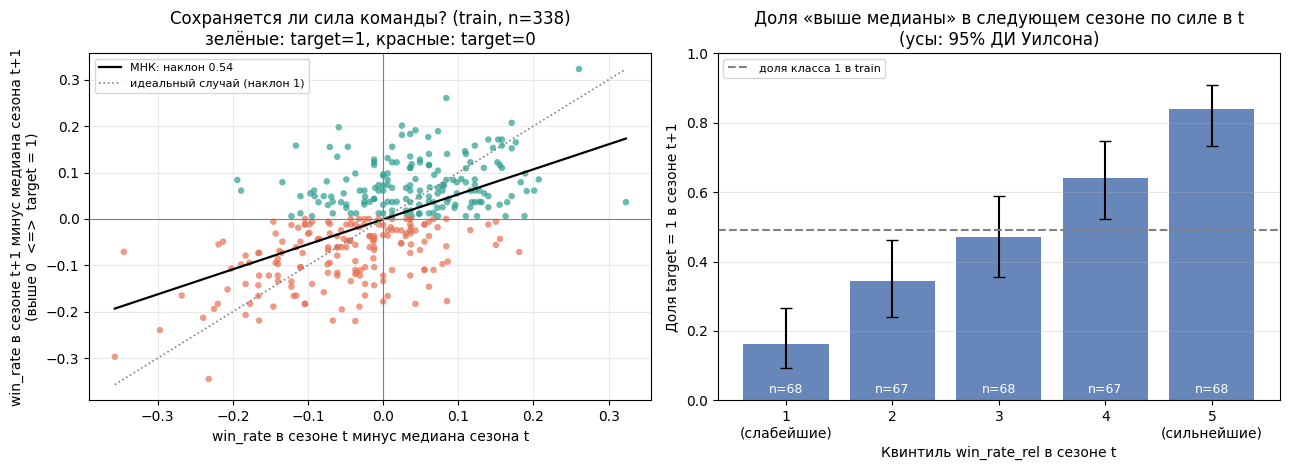

In [20]:
# 3.2-a. Вопрос 1: насколько успех в сезоне t сохраняется в сезоне t+1? (только train)
SEED = 26
rng_boot = np.random.RandomState(SEED)
K = {}

tr = eda_train.copy()
n_tr = len(tr)


def wilson(k, n, z=1.96):
    p = k / n
    den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return c - h, c + h


x, yv = tr["win_rate_rel"].values, tr["next_rel"].values
rho = stats.spearmanr(x, yv)[0]
pear = stats.pearsonr(x, yv)[0]
slope, intercept = np.polyfit(x, yv, 1)
boot_idx = rng_boot.randint(0, n_tr, size=(2000, n_tr))
rho_lo, rho_hi = np.percentile([stats.spearmanr(x[i], yv[i])[0] for i in boot_idx], [2.5, 97.5])
slope_lo, slope_hi = np.percentile([np.polyfit(x[i], yv[i], 1)[0] for i in boot_idx], [2.5, 97.5])
print("Корреляция win_rate_rel(t) и (win_rate(t+1) - медиана(t+1)):")
print("  Спирмен  = %.3f  (95%% bootstrap: %.3f ... %.3f)" % (rho, rho_lo, rho_hi))
print("  Пирсон   = %.3f" % pear)
print("  Наклон регрессии = %.3f  (95%% bootstrap: %.3f ... %.3f); 1.0 означало бы полное сохранение силы"
      % (slope, slope_lo, slope_hi))

tr["above_t"] = tr["win_rate_rel"] > 0
pers = tr.groupby("above_t")["target"].agg(n="size", target1="sum", share_target1="mean")
pers.index = ["не выше медианы в t", "выше медианы в t"]
pers["ДИ 95% (Уилсон)"] = [tuple(np.round(wilson(int(k), int(n)), 3)) for k, n in zip(pers["target1"], pers["n"])]
display(pers)
naive_acc = float((tr["above_t"].astype(int) == tr["target"]).mean())
print("Точность правила «выше медианы в t -> target=1» на train: %.3f (доля класса 1: %.3f)"
      % (naive_acc, tr["target"].mean()))


tr["quintile"] = pd.qcut(tr["win_rate_rel"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
qt = tr.groupby("quintile").agg(n=("target", "size"), win_rate_rel_t=("win_rate_rel", "mean"),
                                next_rel=("next_rel", "mean"), share_target1=("target", "mean"))
qt["ci_low"], qt["ci_high"] = zip(*[wilson(int(tr.loc[tr["quintile"] == q, "target"].sum()), int(n))
                                    for q, n in zip(qt.index, qt["n"])])
display(qt.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
cols = np.where(tr["target"] == 1, "#2a9d8f", "#e76f51")
ax[0].scatter(x, yv, c=cols, s=22, alpha=0.7, edgecolor="none")
xs = np.linspace(x.min(), x.max(), 50)
ax[0].plot(xs, intercept + slope * xs, color="black", lw=1.6, label="МНК: наклон %.2f" % slope)
ax[0].plot(xs, xs, color="grey", ls=":", lw=1.2, label="идеальный случай (наклон 1)")
ax[0].axhline(0, color="grey", lw=0.8)
ax[0].axvline(0, color="grey", lw=0.8)
ax[0].set_xlabel("win_rate в сезоне t минус медиана сезона t")
ax[0].set_ylabel("win_rate в сезоне t+1 минус медиана сезона t+1\n(выше 0  <=>  target = 1)")
ax[0].set_title("Сохраняется ли сила команды? (train, n=%d)\nзелёные: target=1, красные: target=0" % n_tr)
ax[0].legend(loc="upper left", fontsize=8)
ax[0].grid(alpha=0.25)

ax[1].bar(qt.index, qt["share_target1"], color="#4C72B0", alpha=0.85)
ax[1].errorbar(qt.index, qt["share_target1"],
               yerr=[qt["share_target1"] - qt["ci_low"], qt["ci_high"] - qt["share_target1"]],
               fmt="none", ecolor="black", capsize=4)
ax[1].axhline(tr["target"].mean(), color="grey", ls="--", label="доля класса 1 в train")
for q, (s, n) in zip(qt.index, zip(qt["share_target1"], qt["n"])):
    ax[1].text(q, 0.02, "n=%d" % n, ha="center", color="white", fontsize=9)
ax[1].set_xticks(qt.index)
ax[1].set_xticklabels(["1\n(слабейшие)", "2", "3", "4", "5\n(сильнейшие)"])
ax[1].set_ylim(0, 1)
ax[1].set_xlabel("Квинтиль win_rate_rel в сезоне t")
ax[1].set_ylabel("Доля target = 1 в сезоне t+1")
ax[1].set_title("Доля «выше медианы» в следующем сезоне по силе в t\n(усы: 95% ДИ Уилсона)")
ax[1].legend(loc="upper left", fontsize=8)
ax[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

K.update(rho=rho, rho_lo=rho_lo, rho_hi=rho_hi, slope=slope, slope_lo=slope_lo, slope_hi=slope_hi,
         p_above=pers.loc["выше медианы в t", "share_target1"], p_below=pers.loc["не выше медианы в t", "share_target1"],
         naive_acc=naive_acc, q1=qt.loc[1, "share_target1"], q5=qt.loc[5, "share_target1"])

,ROC-AUC (train),ДИ 2.5%,ДИ 97.5%
wins (сырое число побед),0.754,0.702,0.803
win_rate (сырой),0.778,0.729,0.824
win_rate − медиана сезона,0.779,0.730,0.825
goal_diff (сырой),0.777,0.728,0.823
goal_diff на матч,0.776,0.728,0.823
атака: GF на матч − лига,0.720,0.665,0.770
защита: лига − GA на матч,0.719,0.663,0.769


AUC(goal_diff на матч) − AUC(win_rate − медиана сезона) = -0.002   95% bootstrap: -0.023 ... 0.018
Доля bootstrap-выборок, где первый показатель лучше второго: 0.42


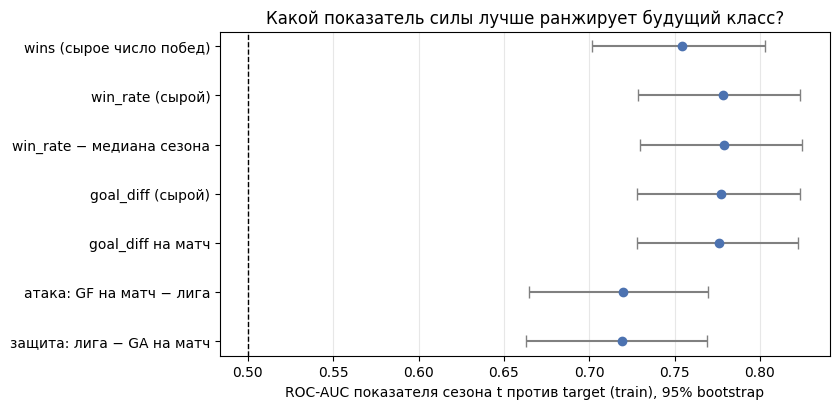

Ранговые корреляции показателей сезона t между собой (train):


,wins (сырое число побед),win_rate (сырой),win_rate − медиана сезона,goal_diff (сырой),goal_diff на матч,атака: GF на матч − лига,защита: лига − GA на матч
wins (сырое число побед),1.00,0.91,0.88,0.88,0.86,0.71,0.66
win_rate (сырой),0.91,1.00,0.99,0.94,0.94,0.76,0.73
win_rate − медиана сезона,0.88,0.99,1.00,0.93,0.94,0.75,0.73
goal_diff (сырой),0.88,0.94,0.93,1.00,1.00,0.78,0.80
goal_diff на матч,0.86,0.94,0.94,1.00,1.00,0.78,0.80
атака: GF на матч − лига,0.71,0.76,0.75,0.78,0.78,1.00,0.29
защита: лига − GA на матч,0.66,0.73,0.73,0.80,0.80,0.29,1.00


In [21]:
# 3.2-b. Вопрос 1 (продолжение): какой показатель силы в сезоне t лучше ранжирует будущий класс?

def fast_auc(y, s):
    r = rankdata(s)
    n1 = int(y.sum())
    n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


SCORES = {
    "wins (сырое число побед)": "wins",
    "win_rate (сырой)": "win_rate",
    "win_rate − медиана сезона": "win_rate_rel",
    "goal_diff (сырой)": "goal_diff",
    "goal_diff на матч": "goal_diff_pg",
    "атака: GF на матч − лига": "attack_rel",
    "защита: лига − GA на матч": "defense_rel",
}
y_tr = tr["target"].values
assert abs(fast_auc(y_tr, tr["win_rate"].values) - roc_auc_score(y_tr, tr["win_rate"])) < 1e-12

bi = np.random.RandomState(SEED).randint(0, n_tr, size=(2000, n_tr))
auc_pt, auc_ci, auc_boot = {}, {}, {}
for name, col in SCORES.items():
    v = tr[col].values
    auc_pt[name] = fast_auc(y_tr, v)
    auc_boot[name] = np.array([fast_auc(y_tr[i], v[i]) for i in bi])
    auc_ci[name] = np.percentile(auc_boot[name], [2.5, 97.5])

auc_tbl = pd.DataFrame({"ROC-AUC (train)": auc_pt,
                        "ДИ 2.5%": {k: v[0] for k, v in auc_ci.items()},
                        "ДИ 97.5%": {k: v[1] for k, v in auc_ci.items()}}).round(3)
display(auc_tbl)

A, Bn = "goal_diff на матч", "win_rate − медиана сезона"
d = auc_boot[A] - auc_boot[Bn]
d_lo, d_hi = np.percentile(d, [2.5, 97.5])
print("AUC(%s) − AUC(%s) = %.3f   95%% bootstrap: %.3f ... %.3f" % (A, Bn, auc_pt[A] - auc_pt[Bn], d_lo, d_hi))
print("Доля bootstrap-выборок, где первый показатель лучше второго: %.2f" % (d > 0).mean())

fig, ax = plt.subplots(figsize=(8.5, 4.2))
names = list(SCORES)[::-1]
pos = np.arange(len(names))
vals = np.array([auc_pt[k] for k in names])
lo = vals - np.array([auc_ci[k][0] for k in names])
hi = np.array([auc_ci[k][1] for k in names]) - vals
ax.errorbar(vals, pos, xerr=[lo, hi], fmt="o", color="#4C72B0", ecolor="grey", capsize=4)
ax.axvline(0.5, color="black", ls="--", lw=1)
ax.set_yticks(pos)
ax.set_yticklabels(names)
ax.set_xlabel("ROC-AUC показателя сезона t против target (train), 95% bootstrap")
ax.set_title("Какой показатель силы лучше ранжирует будущий класс?")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

corr = tr[list(SCORES.values())].corr(method="spearman")
corr.index = corr.columns = list(SCORES)
print("Ранговые корреляции показателей сезона t между собой (train):")
display(corr.round(2))

K.update(auc_wr=auc_pt["win_rate (сырой)"], auc_wr_rel=auc_pt[Bn], auc_wr_rel_lo=auc_ci[Bn][0], auc_wr_rel_hi=auc_ci[Bn][1],
         auc_gd=auc_pt["goal_diff (сырой)"], auc_gd_pg=auc_pt[A], auc_gd_pg_lo=auc_ci[A][0], auc_gd_pg_hi=auc_ci[A][1],
         auc_diff=auc_pt[A] - auc_pt[Bn], auc_diff_lo=d_lo, auc_diff_hi=d_hi,
         corr_wr_gd=corr.loc[Bn, A])

,teams,games,mean_win_rate,median_win_rate,доля матчей без победы и без поражения,league_goals_pg
year,,,,,,
1990,21,80,0.433,0.425,0.133,3.455
1991,22,80,0.433,0.444,0.133,3.479
1992,24,84,0.450,0.476,0.099,3.626
1993,26,84,0.436,0.464,0.128,3.242
1994,26,48,0.440,0.428,0.120,2.986
1995,26,82,0.436,0.433,0.129,3.143
1996,26,82,0.432,0.427,0.135,2.916
1997,26,82,0.423,0.427,0.155,2.638
1998,27,82,0.427,0.415,0.146,2.633


Порог = медиана win_rate в train-парах: 0.439
Средняя по сезонам доля команд с win_rate > порога: train 0.48, validation 0.73


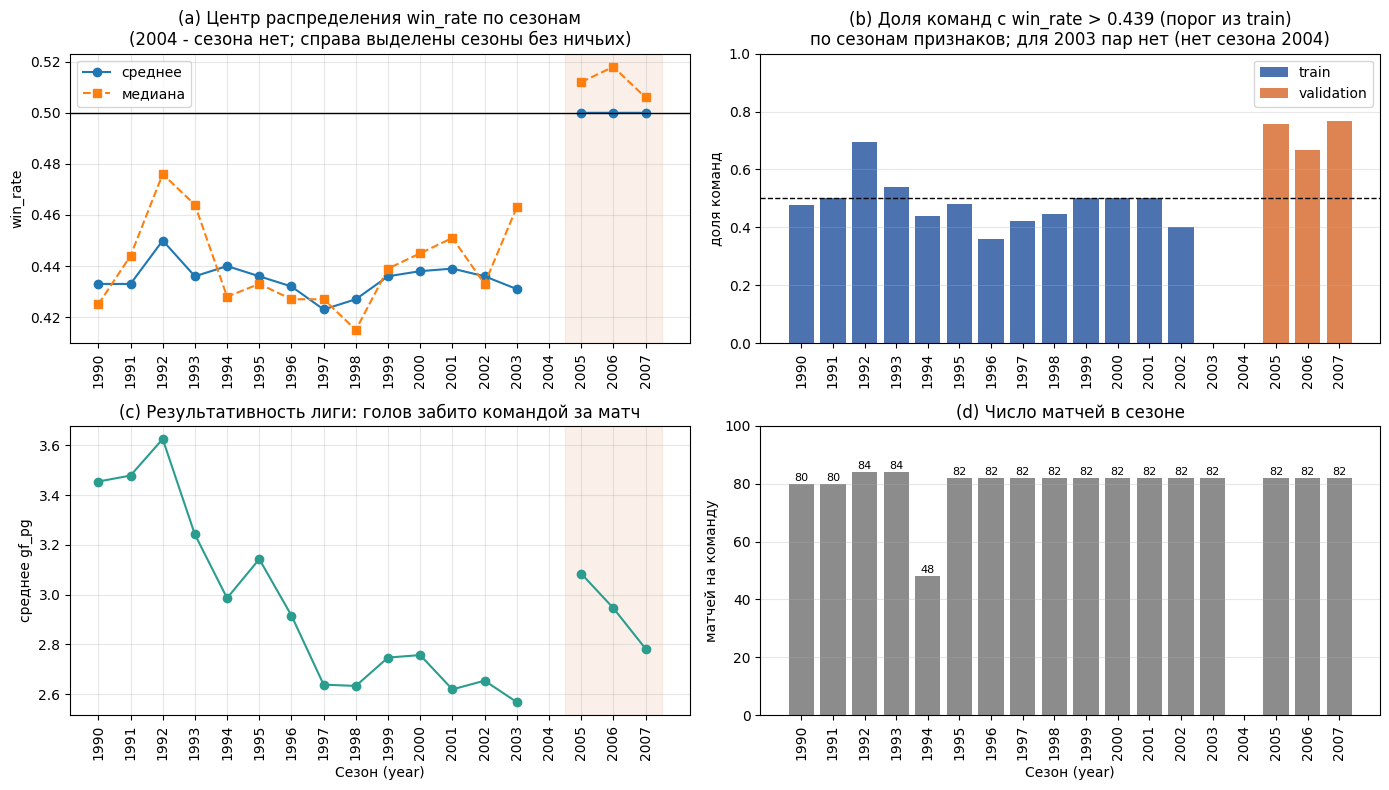

Число train-пар по длине сезона t (матчей): {48: 25, 80: 43, 82: 221, 84: 49}
Доля train-пар, где сезон t не из 82 матчей: 0.346


,team,year,games,wins,win_rate,goals_for,goals_against,goal_diff,goal_diff_pg,win_rate_rel
99,Detroit Red Wings,1994,48,33,0.688,180,117,63,1.312,0.260
126,Detroit Red Wings,1995,82,62,0.756,325,181,144,1.756,0.323


Сырая goal_diff выросла в 2.29 раза, goal_diff на матч - в 1.34 раза, win_rate - в 1.10 раза


In [22]:
# 3.2-c. Вопрос 2: сопоставимы ли признаки между сезонами и между эпохами?
fe = feat[feat["year"] <= 2007]
season_tbl = fe.groupby("year").agg(
    teams=("team", "size"), games=("games", "first"),
    mean_win_rate=("win_rate", "mean"), median_win_rate=("win_rate", "median"),
    other_share=("other_share", "mean"), league_goals_pg=("gf_pg", "mean"),
).round(3)
season_tbl = season_tbl.rename(columns={"other_share": "доля матчей без победы и без поражения"})
display(season_tbl)

thr = eda_train["win_rate"].median()
feat_years = pd.concat([eda_train.assign(part="train")[["year", "win_rate", "part"]],
                        eda_valid.assign(part="validation")[["year", "win_rate", "part"]]])
share_above = feat_years.groupby(["part", "year"])["win_rate"].apply(lambda s: (s > thr).mean()).reset_index(name="share")
by_part = share_above.groupby("part")["share"].mean()
print("Порог = медиана win_rate в train-парах: %.3f" % thr)
print("Средняя по сезонам доля команд с win_rate > порога: train %.2f, validation %.2f" % (by_part["train"], by_part["validation"]))

all_years = list(range(1990, 2008))
st = season_tbl.reindex(all_years)
col_part = {"train": "#4C72B0", "validation": "#dd8452"}

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
a = ax[0, 0]
a.plot(all_years, st["mean_win_rate"], "o-", label="среднее")
a.plot(all_years, st["median_win_rate"], "s--", label="медиана")
a.axhline(0.5, color="black", lw=1)
a.axvspan(2004.5, 2007.5, color="#dd8452", alpha=0.12)
a.set_title("(a) Центр распределения win_rate по сезонам\n(2004 - сезона нет; справа выделены сезоны без ничьих)")
a.set_ylabel("win_rate")
a.legend()
a.grid(alpha=0.3)

a = ax[0, 1]
for part, g in share_above.groupby("part"):
    a.bar(g["year"], g["share"], color=col_part[part], label=part)
a.axhline(0.5, color="black", ls="--", lw=1)
a.set_title("(b) Доля команд с win_rate > %.3f (порог из train)\nпо сезонам признаков; для 2003 пар нет (нет сезона 2004)" % thr)
a.set_ylabel("доля команд")
a.set_ylim(0, 1)
a.legend()
a.grid(axis="y", alpha=0.3)

a = ax[1, 0]
a.plot(all_years, st["league_goals_pg"], "o-", color="#2a9d8f")
a.axvspan(2004.5, 2007.5, color="#dd8452", alpha=0.12)
a.set_title("(c) Результативность лиги: голов забито командой за матч")
a.set_ylabel("среднее gf_pg")
a.grid(alpha=0.3)

a = ax[1, 1]
a.bar(all_years, st["games"], color="#8c8c8c")
for yr, g_ in zip(all_years, st["games"]):
    if not np.isnan(g_):
        a.text(yr, g_ + 1, int(g_), ha="center", fontsize=8)
a.set_title("(d) Число матчей в сезоне")
a.set_ylabel("матчей на команду")
a.set_ylim(0, 100)
a.grid(axis="y", alpha=0.3)
for a in ax[1]:
    a.set_xlabel("Сезон (year)")
for a in ax.ravel():
    a.set_xticks(all_years)
    a.tick_params(axis="x", labelrotation=90)
plt.tight_layout()
plt.show()

gc = eda_train["games"].value_counts().sort_index()
print("Число train-пар по длине сезона t (матчей):", gc.to_dict())
print("Доля train-пар, где сезон t не из 82 матчей: %.3f" % (gc.drop(82, errors="ignore").sum() / len(eda_train)))

det = feat[(feat["team"] == "Detroit Red Wings") & feat["year"].isin([1994, 1995])]
display(det[["team", "year", "games", "wins", "win_rate", "goals_for", "goals_against", "goal_diff",
             "goal_diff_pg", "win_rate_rel"]].round(3))
d94, d95 = det.set_index("year").loc[1994], det.set_index("year").loc[1995]
print("Сырая goal_diff выросла в %.2f раза, goal_diff на матч - в %.2f раза, win_rate - в %.2f раза"
      % (d95["goal_diff"] / d94["goal_diff"], d95["goal_diff_pg"] / d94["goal_diff_pg"], d95["win_rate"] / d94["win_rate"]))

K.update(thr=thr, share_train=by_part["train"], share_valid=by_part["validation"],
         gpg_min=season_tbl["league_goals_pg"].min(), gpg_max=season_tbl["league_goals_pg"].max(),
         gpg_min_year=int(season_tbl["league_goals_pg"].idxmin()), gpg_max_year=int(season_tbl["league_goals_pg"].idxmax()),
         mean_wr_ties=fe.loc[fe["year"] <= 2003, "win_rate"].mean(), mean_wr_noties=fe.loc[fe["year"] >= 2005, "win_rate"].mean())

Пар с пропущенным ot_losses: train 220 из 338 (65%), validation 0 из 89
Годы признаков в train-парах с пропуском ot_losses: [1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998]
Годы признаков в train-парах с заполненным ot_losses: [1999, 2000, 2001, 2002]

Подвыборка train с известным ot_losses: 118 пар (feature years 1999-2002)


,показатель,ROC-AUC,ДИ 2.5%,ДИ 97.5%
0,ot_losses на матч (направление не задано заранее),0.456,0.354,0.559
1,win_rate − медиана сезона (для сравнения),0.792,0.707,0.869
2,goal_diff на матч (для сравнения),0.829,0.754,0.898


Спирмен(ot_pg, win_rate_rel) = -0.335: насколько ot_losses просто повторяет силу команды


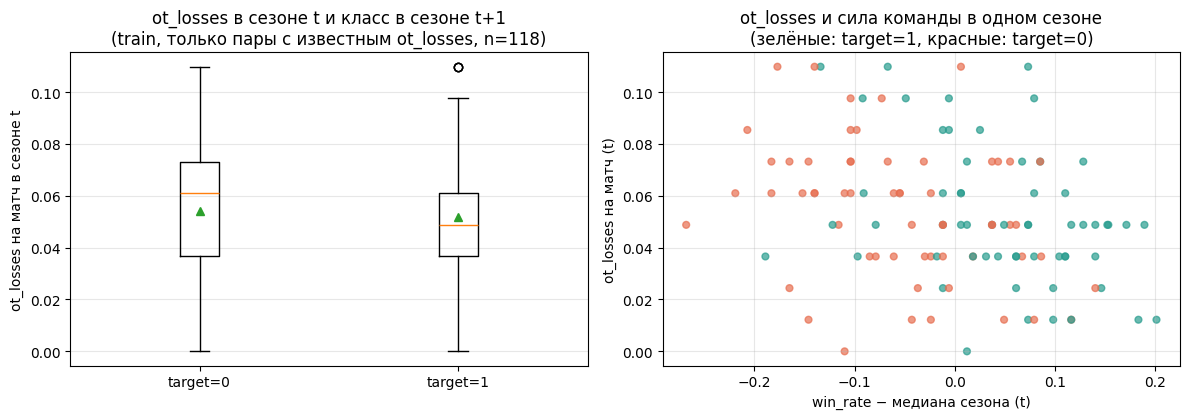

In [23]:
# 3.2-d. Вопрос 3: нужен ли ot_losses, если в train он структурно отсутствует до 1999 года?
n_miss_tr = int(eda_train["ot_missing"].sum())
n_miss_va = int(eda_valid["ot_missing"].sum())
print("Пар с пропущенным ot_losses: train %d из %d (%.0f%%), validation %d из %d"
      % (n_miss_tr, len(eda_train), 100 * n_miss_tr / len(eda_train), n_miss_va, len(eda_valid)))
print("Годы признаков в train-парах с пропуском ot_losses:",
      sorted(int(v) for v in eda_train.loc[eda_train["ot_missing"], "year"].unique()))
print("Годы признаков в train-парах с заполненным ot_losses:",
      sorted(int(v) for v in eda_train.loc[~eda_train["ot_missing"], "year"].unique()))

sub = eda_train[~eda_train["ot_missing"]].reset_index(drop=True)
y_sub = sub["target"].values
bi_sub = np.random.RandomState(SEED).randint(0, len(sub), size=(2000, len(sub)))


def auc_with_ci(values):
    pt = fast_auc(y_sub, values)
    lo, hi = np.percentile([fast_auc(y_sub[i], values[i]) for i in bi_sub], [2.5, 97.5])
    return pt, lo, hi


rows = []
for label, col in [("ot_losses на матч (направление не задано заранее)", "ot_pg"),
                   ("win_rate − медиана сезона (для сравнения)", "win_rate_rel"),
                   ("goal_diff на матч (для сравнения)", "goal_diff_pg")]:
    pt, lo, hi = auc_with_ci(sub[col].values)
    rows.append((label, round(pt, 3), round(lo, 3), round(hi, 3)))
ot_tbl = pd.DataFrame(rows, columns=["показатель", "ROC-AUC", "ДИ 2.5%", "ДИ 97.5%"])
print("\nПодвыборка train с известным ot_losses: %d пар (feature years %d-%d)"
      % (len(sub), sub["year"].min(), sub["year"].max()))
display(ot_tbl)
rho_ot = stats.spearmanr(sub["ot_pg"], sub["win_rate_rel"])[0]
print("Спирмен(ot_pg, win_rate_rel) = %.3f: насколько ot_losses просто повторяет силу команды" % rho_ot)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].boxplot([sub.loc[sub["target"] == 0, "ot_pg"], sub.loc[sub["target"] == 1, "ot_pg"]], showmeans=True)
ax[0].set_xticklabels(["target=0", "target=1"])
ax[0].set_ylabel("ot_losses на матч в сезоне t")
ax[0].set_title("ot_losses в сезоне t и класс в сезоне t+1\n(train, только пары с известным ot_losses, n=%d)" % len(sub))
ax[0].grid(axis="y", alpha=0.3)
ax[1].scatter(sub["win_rate_rel"], sub["ot_pg"], c=np.where(sub["target"] == 1, "#2a9d8f", "#e76f51"), s=24, alpha=0.7)
ax[1].set_xlabel("win_rate − медиана сезона (t)")
ax[1].set_ylabel("ot_losses на матч (t)")
ax[1].set_title("ot_losses и сила команды в одном сезоне\n(зелёные: target=1, красные: target=0)")
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

pt_ot, lo_ot, hi_ot = auc_with_ci(sub["ot_pg"].values)
pt_wr_sub = fast_auc(y_sub, sub["win_rate_rel"].values)
K.update(n_sub=len(sub), n_miss_tr=n_miss_tr, auc_ot=pt_ot, auc_ot_lo=lo_ot, auc_ot_hi=hi_ot,
         auc_wr_rel_sub=pt_wr_sub, rho_ot=rho_ot)

In [24]:
# 3.2-e. Уровень команды/сезона: самые резкие «разворотные» случаи среди train-пар
tr["delta"] = tr["next_rel"] - tr["win_rate_rel"]
show = ["team", "year", "games", "win_rate", "win_rate_rel", "goal_diff_pg", "next_win_rate", "next_rel", "target"]
falls = tr[tr["win_rate_rel"] > 0].nsmallest(4, "delta")        # были выше медианы и сильнее всего просели
rises = tr[tr["win_rate_rel"] <= 0].nlargest(4, "delta")        # были не выше медианы и сильнее всего выросли
print("Сильнее всего просели команды, бывшие выше медианы сезона t:")
display(falls[show].round(3).reset_index(drop=True))
print("Сильнее всего выросли команды, бывшие не выше медианы сезона t:")
display(rises[show].round(3).reset_index(drop=True))

K.update(max_fall=falls["delta"].min(), max_rise=rises["delta"].max())

Сильнее всего просели команды, бывшие выше медианы сезона t:


,team,year,games,win_rate,win_rate_rel,goal_diff_pg,next_win_rate,next_rel,target
0,Detroit Red Wings,1995,82,0.756,0.323,1.756,0.463,0.036,1
1,Florida Panthers,1999,82,0.524,0.085,0.427,0.268,-0.177,0
2,New York Rangers,1991,80,0.625,0.181,0.938,0.405,-0.071,0
3,Washington Capitals,2002,82,0.476,0.043,0.049,0.280,-0.183,0


Сильнее всего выросли команды, бывшие не выше медианы сезона t:


,team,year,games,win_rate,win_rate_rel,goal_diff_pg,next_win_rate,next_rel,target
0,Quebec Nordiques,1991,80,0.250,-0.194,-0.788,0.560,0.084,1
1,San Jose Sharks,1992,84,0.131,-0.345,-2.333,0.393,-0.071,0
2,Dallas Stars,1995,82,0.317,-0.116,-0.646,0.585,0.158,1
3,Quebec Nordiques,1993,84,0.405,-0.059,-0.179,0.625,0.198,1


In [25]:
# 3.2-f. Сводка чисел раздела 3 и проверка утверждений, которые записаны в ответах 3.1 и 3.2
key_numbers = pd.Series(K).rename("значение")
display(key_numbers.round(3).to_frame())

checks = [
    # ожидания, записанные в 3.1 до построения графиков
    ("ожидание 3.1, Q1", "Спирмен(win_rate_rel, next_rel) в диапазоне 0.3-0.5", K["rho"], 0.3 <= K["rho"] <= 0.5),
    ("ожидание 3.1, Q1", "доля target=1 среди «выше медианы в t» в диапазоне 0.60-0.70", K["p_above"], 0.60 <= K["p_above"] <= 0.70),
    ("ожидание 3.1, Q1", "ROC-AUC win_rate_rel в диапазоне 0.6-0.7", K["auc_wr_rel"], 0.6 <= K["auc_wr_rel"] <= 0.7),
    ("ожидание 3.1, Q1", "|AUC(goal_diff_pg) - AUC(win_rate_rel)| не больше 0.03", K["auc_diff"], abs(K["auc_diff"]) <= 0.03),
    ("ожидание 3.1, Q2", "доля команд выше порога train в validation больше 0.60", K["share_valid"], K["share_valid"] > 0.60),
    ("ожидание 3.1, Q3", "ROC-AUC ot_losses на подвыборке в диапазоне 0.45-0.55", K["auc_ot"], 0.45 <= K["auc_ot"] <= 0.55),
    # утверждения из ответа 3.2
    ("вывод 3.2, Q1", "связь положительна: нижняя граница ДИ Спирмена больше 0", K["rho_lo"], K["rho_lo"] > 0),
    ("вывод 3.2, Q1", "наклон меньше 1: верхняя граница ДИ меньше 1", K["slope_hi"], K["slope_hi"] < 1),
    ("вывод 3.2, Q1", "доля target=1 в «выше медианы» больше, чем в «не выше»", K["p_above"] - K["p_below"], K["p_above"] > K["p_below"]),
    ("вывод 3.2, Q1", "доля target=1 в 5-м квинтиле больше, чем в 1-м", K["q5"] - K["q1"], K["q5"] > K["q1"]),
    ("вывод 3.2, Q1", "AUC win_rate_rel лучше случайного: нижняя граница ДИ больше 0.5", K["auc_wr_rel_lo"], K["auc_wr_rel_lo"] > 0.5),
    ("вывод 3.2, Q1", "AUC goal_diff_pg лучше случайного: нижняя граница ДИ больше 0.5", K["auc_gd_pg_lo"], K["auc_gd_pg_lo"] > 0.5),
    ("вывод 3.2, Q1", "в 5-м квинтиле доля target=1 меньше 0.9 (сохранение далеко от 100%)", K["q5"], K["q5"] < 0.9),
    ("вывод 3.2, Q1", "разность AUC не отличима от нуля: ДИ содержит 0", K["auc_diff"], K["auc_diff_lo"] < 0 < K["auc_diff_hi"]),
    ("вывод 3.2, Q1", "win_rate_rel и goal_diff_pg сильно связаны: Спирмен больше 0.7", K["corr_wr_gd"], K["corr_wr_gd"] > 0.7),
    ("вывод 3.2, Q2", "средний win_rate до 2004 ниже 0.46, а в 2005-2007 в пределах 0.50 ± 0.01",
     K["mean_wr_ties"], K["mean_wr_ties"] < 0.46 and abs(K["mean_wr_noties"] - 0.5) < 0.01),
    ("вывод 3.2, Q3", "ДИ ROC-AUC ot_losses содержит 0.5", K["auc_ot"], K["auc_ot_lo"] <= 0.5 <= K["auc_ot_hi"]),
]
chk = pd.DataFrame(checks, columns=["источник", "утверждение", "значение", "выполнено"])
chk["значение"] = chk["значение"].round(3)
display(chk)
print("Невыполнено:", int((~chk["выполнено"]).sum()), "из", len(chk))

,значение
rho,0.531
rho_lo,0.443
rho_hi,0.605
slope,0.539
slope_lo,0.449
slope_hi,0.625
p_above,0.706
p_below,0.291
naive_acc,0.707
q1,0.162


,источник,утверждение,значение,выполнено
0,"ожидание 3.1, Q1","Спирмен(win_rate_rel, next_rel) в диапазоне 0....",0.531,False
1,"ожидание 3.1, Q1",доля target=1 среди «выше медианы в t» в диапа...,0.706,False
2,"ожидание 3.1, Q1",ROC-AUC win_rate_rel в диапазоне 0.6-0.7,0.779,False
3,"ожидание 3.1, Q1",|AUC(goal_diff_pg) - AUC(win_rate_rel)| не бол...,-0.002,True
4,"ожидание 3.1, Q2",доля команд выше порога train в validation бол...,0.731,True
5,"ожидание 3.1, Q3",ROC-AUC ot_losses на подвыборке в диапазоне 0....,0.456,True
6,"вывод 3.2, Q1",связь положительна: нижняя граница ДИ Спирмена...,0.443,True
7,"вывод 3.2, Q1",наклон меньше 1: верхняя граница ДИ меньше 1,0.625,True
8,"вывод 3.2, Q1","доля target=1 в «выше медианы» больше, чем в «...",0.414,True
9,"вывод 3.2, Q1","доля target=1 в 5-м квинтиле больше, чем в 1-м",0.676,True


Невыполнено: 3 из 17


**Ответ 3.2:**

**Вопрос 1 — сохраняется ли сила команды?** На train (338 пар) связь между win_rate_rel сезона t и относительной успешностью в t+1 положительная: коэффициент Спирмена 0,531, 95%-й bootstrap-интервал [0,443; 0,605]. Линейный наклон равен 0,539 с интервалом [0,449; 0,625]; он заметно меньше 1, то есть разница в силе относительно лиги в среднем сохраняется лишь частично. Если команда была выше медианы в сезоне t, доля target=1 в следующем сезоне составила 0,706 (115 из 163, 95%-й интервал Уилсона [0,631; 0,770]). Если команда была не выше медианы, эта доля составила 0,291 (51 из 175; [0,229; 0,363]). На графике «Сохраняется ли сила команды?» и графике долей по квинтилям виден тот же градиент: доля target=1 выросла от 0,162 в первом квинтиле до 0,838 в пятом. Значит, прошлый результат информативен, но даже сильнейшая группа не имеет гарантии успеха в следующем году.

При оценке простых показателей на train ROC-AUC win_rate_rel составил 0,779 (95%-й bootstrap-интервал [0,730; 0,825]), а goal_diff_pg — 0,776 ([0,728; 0,823]). Разность AUC goal_diff_pg − win_rate_rel равна −0,002, её 95%-й интервал [−0,023; 0,018] включает ноль; по этим данным нельзя уверенно объявить один показатель лучше другого. Эти два признака также сильно связаны между собой (ранговая корреляция Спирмена 0,935), поэтому они во многом отражают общий сигнал о силе команды. Ожидания не подтвердились сразу по нескольким числам: коэффициент Спирмена 0,531 немного выше ожидаемого диапазона 0,3–0,5, доля target=1 среди команд выше медианы — 0,706, то есть чуть выше верхней границы 0,70, а AUC 0,779 и 0,776 для простых признаков заметно выше ожидавшихся 0,6–0,7. Это не опровергает основной вывод, но показывает, что предварительные диапазоны были слишком узкими/низкими. Эти AUC рассчитаны на train и потому не заменяют оценку на отложенных данных.

**Вопрос 2 — сопоставимы ли сезоны?** Сезоны различаются по числу матчей: в train-парах 34,6% наблюдений относятся к сезонам не из 82 матчей; встречаются сезоны по 80, 84 и даже 48 матчей. Нет данных за 2004 год. На графике сезонной динамики виден и сдвиг win_rate: среднее значение по строкам до 2004 года составляет примерно 0,435, а в сезонах 2005–2007 — 0,500. Доля матчей, не обозначенных ни как победы, ни как поражения, была около 0,10–0,16 в ранних сезонах, но стала нулевой с 2005 года. Кроме того, при пороге win_rate=0,439, взятом по train-парам, средняя по сезонам доля команд выше порога составляет 0,48 в train и 0,73 в validation. Это подтверждает сдвиг распределения между временными периодами и поддерживает использование относительных и рассчитанных на матч признаков.

Конкретный пример — Detroit Red Wings: в 1994 году команда сыграла 48 матчей, имела goal_diff=63 и goal_diff_pg=1,312; в 1995 году — 82 матча, goal_diff=144 и goal_diff_pg=1,756. Сырой goal_diff вырос в 2,29 раза, тогда как разность голов на матч — в 1,34 раза, а win_rate — в 1,10 раза. Сравнение необработанных итогов в этом случае преувеличивает масштаб изменения. Эти сезонные различия показывают, что нормализация нужна, но сами по себе не доказывают причины сдвига и не гарантируют переносимость признаков в будущие годы.

**Вопрос 3 — полезен ли ot_losses?** В train у 220 из 338 пар (65%) значение отсутствует; все эти пропуски приходятся на сезоны признаков 1990–1998 годов. В validation пропусков нет, поскольку там представлены сезоны признаков 2005–2007 годов. На подвыборке из 118 train-пар с известным значением (сезоны признаков 1999–2002) ROC-AUC ot_losses на матч равен 0,456, 95%-й bootstrap-интервал — [0,354; 0,559]. Интервал содержит 0,5, поэтому убедительного самостоятельного ранжирующего сигнала не обнаружено. Для сравнения, на той же подвыборке AUC win_rate_rel равен 0,792 ([0,707; 0,869]), а goal_diff_pg — 0,829 ([0,754; 0,898]). Связь ot_pg с win_rate_rel отрицательна и умеренна (Спирмен −0,335), но это не означает причинного эффекта поражений в овертайме.

При этом пропуски ot_losses нельзя заменять нулями: ноль означает наблюдаемое отсутствие таких поражений, а пропуск - отсутствие показателя в части исходных сезонов. EDA не доказывает отдельную пользу ot_pg, поэтому самым разумным решением обработи пропусков в будущей модели будет полное исключение этого признака.

EDA поддерживает нормализацию признаков, использование win_rate_rel и goal_diff_pg, временное разделение (есть изменение распределений данных) и обработку пропусков через исключение признака. Главные ограничения - небольшое число пар, повторные наблюдения одних команд в разные годы и то, что доверительные интервалы bootstrap на уровне отдельных строк не учитывают полностью зависимость наблюдений одной команды во времени.


## Раздел 4. Модели и эксперименты: 25 баллов

### 4.1. Постройте ориентиры

На train обучите простой константный baseline и оцените его на validation.
Отдельно используйте текущий `win_rate` как простую оценку для ранжирования
будущего класса. Посчитайте ROC-AUC обоих ориентиров и объясните,
какую планку задаёт каждый из них для обучаемой модели.

In [26]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score

y_train_41 = train["target"].astype(int)
y_valid_41 = valid["target"].astype(int)
constant_baseline = DummyClassifier(strategy="prior")
constant_baseline.fit(train[["win_rate"]], y_train_41)
constant_scores_valid = constant_baseline.predict_proba(valid[["win_rate"]])[:, 1]

win_rate_scores_valid = valid["win_rate"].to_numpy()
auc_constant_valid = roc_auc_score(y_valid_41, constant_scores_valid)
auc_win_rate_valid = roc_auc_score(y_valid_41, win_rate_scores_valid)

baseline_results = pd.DataFrame({
    "Ориентир": ["Константный DummyClassifier (prior)", "win_rate сезона t (ранжирование)"],
    "ROC-AUC validation": [auc_constant_valid, auc_win_rate_valid],
})
display(baseline_results.round(3))


,Ориентир,ROC-AUC validation
0,Константный DummyClassifier (prior),0.500
1,win_rate сезона t (ранжирование),0.757


**Ответ 4.1:**

Константный DummyClassifier(strategy="prior") выдаёт одинаковую оценку всем командам. Поэтому он не умеет ранжировать команды и даёт ROC-AUC 0.500 — это ориентир случайного ранжирования. Текущий win_rate сезона t без обучения модели даёт ROC-AUC около 0.757 на validation. Это ориентир: обучаемой модели желательно также показать пользу относительно текущего win_rate, а иначе она не будет иметь большого смысла.

### 4.2. Постройте первую модель

Обучите логистическую регрессию. Самостоятельно выберите признаки и обоснуйте выбор.
Обработку пропусков и масштабирование включите в Pipeline и обучайте только на train.
Посчитайте ROC-AUC на validation и сравните с обоими ориентирами.
Объясните результат без использования test.

In [27]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

MODEL_FEATURES = ["win_rate_rel", "goal_diff_pg", "ot_pg"]
assert not set(MODEL_FEATURES) & set(LEAKY_COLS)

train_model = pairs_x[pairs_x["split"] == "train"].copy()
valid_model = pairs_x[pairs_x["split"] == "validation"].copy()
X_train_model = train_model[MODEL_FEATURES]
y_train_model = train_model["target"].astype(int)
X_valid_model = valid_model[MODEL_FEATURES]
y_valid_model = valid_model["target"].astype(int)

logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(C=1.0, max_iter=2000, random_state=26)),
])
logistic_pipeline.fit(X_train_model, y_train_model)
logistic_scores_valid = logistic_pipeline.predict_proba(X_valid_model)[:, 1]
auc_logistic_valid = roc_auc_score(y_valid_model, logistic_scores_valid)

comparison_26 = pd.DataFrame({
    "Модель / ориентир": ["Константный baseline", "win_rate сезона t", "Логистическая регрессия"],
    "ROC-AUC validation": [auc_constant_valid, auc_win_rate_valid, auc_logistic_valid],
})
display(comparison_26.round(3))
print("Признаки модели:", MODEL_FEATURES)
print("Пропуски ot_pg в train: %d из %d; обрабатываются медианой, Pipeline добавляет индикатор пропуска." %
      (int(X_train_model["ot_pg"].isna().sum()), len(X_train_model)))
print("ROC-AUC логистической регрессии на validation = %.3f." % auc_logistic_valid)

coef_names = logistic_pipeline.named_steps["imputer"].get_feature_names_out(MODEL_FEATURES)
coef_values = logistic_pipeline.named_steps["classifier"].coef_[0]
coef_table = pd.DataFrame({"Признак": coef_names, "Коэффициент LogisticRegression": coef_values})
display(coef_table.round(3))
cor_spearman = train_model[["win_rate_rel", "goal_diff_pg"]].corr(method="spearman").iloc[0, 1]
cor_pearson = train_model[["win_rate_rel", "goal_diff_pg"]].corr(method="pearson").iloc[0, 1]
print("Корреляция признаков win_rate_rel и goal_diff_pg на train: Спирмен %.3f; Пирсон %.3f." %
      (cor_spearman, cor_pearson))

,Модель / ориентир,ROC-AUC validation
0,Константный baseline,0.500
1,win_rate сезона t,0.757
2,Логистическая регрессия,0.755


Признаки модели: ['win_rate_rel', 'goal_diff_pg', 'ot_pg']
Пропуски ot_pg в train: 220 из 338; обрабатываются медианой, Pipeline добавляет индикатор пропуска.
ROC-AUC логистической регрессии на validation = 0.755.


,Признак,Коэффициент LogisticRegression
0,win_rate_rel,0.884
1,goal_diff_pg,0.454
2,ot_pg,0.167
3,missingindicator_ot_pg,-0.019


Корреляция признаков win_rate_rel и goal_diff_pg на train: Спирмен 0.935; Пирсон 0.937.


**Ответ 4.2:**

Для логистической регрессии выбраны win_rate_rel, goal_diff_pg как потенциально самые сильные признаки. Так как данным немного, и признаки имеют друг с другом большие корреляции, то брать большое количество признаков не стоит из-за риска переобучения и проблем мультиколлинеарность. Отдельно был взят дополнительно признак ot_pg в качестве эксперимента (позже будет оценена его польза).

Пропуски обрабатываются через медиану и индикатор пропуска. Масштабирование находятся внутри Pipeline; все преобразования обучаются только на train. ROC-AUC логистической регрессии на validation — 0,755: она немного уступает простому win_rate (0,757), то есть линейная модель с выбранным набором признаков не дала выигрыша над baseline.

Коэффициенты после импутации и стандартизации: win_rate_rel +0,884, goal_diff_pg +0,454, ot_pg +0,167, missingindicator_ot_pg −0,019. Первые два признака сильно коррелируют на train (Спирмен 0,935, Пирсон 0,937), поэтому их коэффициенты нельзя интерпретировать как два независимых эффекта или напрямую сравнивать как меру важности. Индикатор пропуска имеет маленький коэффициент, но сам факт пропуска связан с историческим периодом; кроме того, в validation/test пропусков ot_pg нет. Значит имеет смысл оценить ot_pg в следующем эксперименте, а не делать вывод о его полезности только по коэффициентам.

### 4.3. Проведите собственный эксперимент

Выберите одно осмысленное изменение: состав признаков, способ обработки данных,
параметры или другой алгоритм. До запуска запишите ожидаемый эффект и его причину.
Изменяйте одну понятную часть решения, сравните варианты на validation
и зафиксируйте выбор финальной модели до просмотра test.
Дополнительные эксперименты допустимы, но их количество само по себе не оценивается.

Гипотеза: неглубокий ансамбль деревьев (ExtraTreesClassifier) может уловить нелинейности, которых не хватает логистической регресии.

Также проверим гипотезу о том, что признак ot_pg не даст улучшения модели.

In [28]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import roc_auc_score

MODEL_FEATURES_NO_OT = ["win_rate_rel", "goal_diff_pg"]
assert not set(MODEL_FEATURES_NO_OT) & set(LEAKY_COLS)

extra_trees_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("classifier", ExtraTreesClassifier(
        n_estimators=300,
        max_depth=3,
        min_samples_leaf=5,
        max_features=1.0,
        random_state=26,
        n_jobs=-1,
    )),
])
extra_trees_pipeline.fit(train_model[MODEL_FEATURES], y_train_model)
extra_trees_scores_valid = extra_trees_pipeline.predict_proba(valid_model[MODEL_FEATURES])[:, 1]
auc_extra_trees_valid = roc_auc_score(y_valid_model, extra_trees_scores_valid)

extra_trees_no_ot_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("classifier", ExtraTreesClassifier(
        n_estimators=300,
        max_depth=3,
        min_samples_leaf=5,
        max_features=1.0,
        random_state=26,
        n_jobs=-1,
    )),
])
extra_trees_no_ot_pipeline.fit(train_model[MODEL_FEATURES_NO_OT], y_train_model)
extra_trees_no_ot_scores_valid = extra_trees_no_ot_pipeline.predict_proba(valid_model[MODEL_FEATURES_NO_OT])[:, 1]
auc_extra_trees_no_ot_valid = roc_auc_score(y_valid_model, extra_trees_no_ot_scores_valid)

comparison_43 = pd.DataFrame({
    "Модель / ориентир": [
        "Константный baseline", "win_rate сезона t", "Логистическая регрессия",
        "ExtraTrees: с ot_pg", "ExtraTrees: без ot_pg",
    ],
    "ROC-AUC validation": [
        auc_constant_valid, auc_win_rate_valid, auc_logistic_valid,
        auc_extra_trees_valid, auc_extra_trees_no_ot_valid,
    ],
})
display(comparison_43.round(3))

print("Абляция ot_pg: ROC-AUC с признаком %.3f; без признака %.3f; падение после удаления %.3f." % (
    auc_extra_trees_valid, auc_extra_trees_no_ot_valid,
    auc_extra_trees_valid - auc_extra_trees_no_ot_valid))

cv_folds = [(1996, [1997, 1998]), (1998, [1999, 2000]),
            (2000, [2001, 2002]), (2002, [2003])]
cv_candidates = [
    ("LogisticRegression", MODEL_FEATURES, "lr"),
    ("ExtraTrees с ot_pg", MODEL_FEATURES, "et"),
    ("ExtraTrees без ot_pg", MODEL_FEATURES_NO_OT, "et"),
]
cv_rows = []
for fold_no, (cutoff, validation_years) in enumerate(cv_folds, start=1):
    fold_train = train_model[train_model["target_year"] <= cutoff].copy()
    fold_valid = train_model[train_model["target_year"].isin(validation_years)].copy()
    for label, candidate_features, algorithm in cv_candidates:
        active_features = [col for col in candidate_features if fold_train[col].notna().any()]
        if algorithm == "lr":
            classifier = LogisticRegression(C=1.0, max_iter=2000, random_state=26)
        else:
            classifier = ExtraTreesClassifier(n_estimators=300, max_depth=3, min_samples_leaf=5,
                                              max_features=1.0, random_state=26, n_jobs=-1)
        cv_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler()),
            ("classifier", classifier),
        ])
        cv_pipeline.fit(fold_train[active_features], fold_train["target"].astype(int))
        fold_scores = cv_pipeline.predict_proba(fold_valid[active_features])[:, 1]
        cv_rows.append({
            "Fold": fold_no,
            "Train target_year <=": cutoff,
            "Validation target_year": f"{min(validation_years)}–{max(validation_years)}",
            "Модель": label,
            "Признаки в этом fold": ", ".join(active_features),
            "n train": len(fold_train),
            "n validation": len(fold_valid),
            "ROC-AUC": roc_auc_score(fold_valid["target"], fold_scores),
        })
cv_results = pd.DataFrame(cv_rows)
print("Expanding-window CV на train:")
display(cv_results.round({"ROC-AUC": 3}))
print("Средний ROC-AUC по folds для диагностики стабильности")
display(cv_results.groupby("Модель")["ROC-AUC"].agg(["mean", "std", "min", "max"]).round(3))

if auc_extra_trees_valid > auc_logistic_valid:
    if (auc_extra_trees_valid - auc_extra_trees_no_ot_valid) < 0.01:
        FINAL_MODEL_NAME = "ExtraTreesClassifier (без ot_pg)"
        FINAL_MODEL = extra_trees_no_ot_pipeline
        FINAL_FEATURES = MODEL_FEATURES_NO_OT.copy()
        SELECTION_REASON = "потеря ROC-AUC при удалении ot_pg < 0.01; выбрана более простая версия"
    else:
        FINAL_MODEL_NAME = "ExtraTreesClassifier"
        FINAL_MODEL = extra_trees_pipeline
        FINAL_FEATURES = MODEL_FEATURES.copy()
        SELECTION_REASON = "версия с ot_pg превосходит абляцию не менее чем на 0.01 ROC-AUC"
else:
    FINAL_MODEL_NAME = "LogisticRegression"
    FINAL_MODEL = logistic_pipeline
    FINAL_FEATURES = MODEL_FEATURES.copy()
    SELECTION_REASON = "логистическая регрессия имеет лучший ROC-AUC на validation"
FINAL_VALIDATION_AUC = roc_auc_score(y_valid_model, FINAL_MODEL.predict_proba(valid_model[FINAL_FEATURES])[:, 1])

print("Выбрана финальная модель:", FINAL_MODEL_NAME)
print("Причина выбора:", SELECTION_REASON)
print("Зафиксированные признаки:", FINAL_FEATURES)
print("ROC-AUC validation = %.3f; test не использовался." % FINAL_VALIDATION_AUC)
print("Test до выбора модели не использовался.")

,Модель / ориентир,ROC-AUC validation
0,Константный baseline,0.500
1,win_rate сезона t,0.757
2,Логистическая регрессия,0.755
3,ExtraTrees: с ot_pg,0.776
4,ExtraTrees: без ot_pg,0.772


Абляция ot_pg: ROC-AUC с признаком 0.776; без признака 0.772; падение после удаления 0.004.
Expanding-window CV на train:


,Fold,Train target_year <=,Validation target_year,Модель,Признаки в этом fold,n train,n validation,ROC-AUC
0,1,1996,1997–1998,LogisticRegression,"win_rate_rel, goal_diff_pg",142,51,0.770
1,1,1996,1997–1998,ExtraTrees с ot_pg,"win_rate_rel, goal_diff_pg",142,51,0.776
2,1,1996,1997–1998,ExtraTrees без ot_pg,"win_rate_rel, goal_diff_pg",142,51,0.776
3,2,1998,1999–2000,LogisticRegression,"win_rate_rel, goal_diff_pg",193,55,0.886
4,2,1998,1999–2000,ExtraTrees с ot_pg,"win_rate_rel, goal_diff_pg",193,55,0.890
5,2,1998,1999–2000,ExtraTrees без ot_pg,"win_rate_rel, goal_diff_pg",193,55,0.890
6,3,2000,2001–2002,LogisticRegression,"win_rate_rel, goal_diff_pg, ot_pg",248,60,0.713
7,3,2000,2001–2002,ExtraTrees с ot_pg,"win_rate_rel, goal_diff_pg, ot_pg",248,60,0.727
8,3,2000,2001–2002,ExtraTrees без ot_pg,"win_rate_rel, goal_diff_pg",248,60,0.733
9,4,2002,2003–2003,LogisticRegression,"win_rate_rel, goal_diff_pg, ot_pg",308,30,0.857


Средний ROC-AUC по folds для диагностики стабильности


,mean,std,min,max
Модель,,,,
ExtraTrees без ot_pg,0.809,0.068,0.733,0.890
ExtraTrees с ot_pg,0.812,0.075,0.727,0.890
LogisticRegression,0.807,0.079,0.713,0.886


Выбрана финальная модель: ExtraTreesClassifier (без ot_pg)
Причина выбора: потеря ROC-AUC при удалении ot_pg < 0.01; выбрана более простая версия
Зафиксированные признаки: ['win_rate_rel', 'goal_diff_pg']
ROC-AUC validation = 0.772; test не использовался.
Test до выбора модели не использовался.


**Ответ 4.3:**

Эксперимент подтвердил, что ExtraTrees даёт более высокий validation ROC-AUC, чем логистическая регрессия: 0,776 против 0,755; ориентир win_rate равен 0,757. Затем проведена абляция: у ExtraTrees без ot_pg ROC-AUC составляет 0,772, то есть снижение относительно полной версии — только 0,004. Оно незначительно, поэтому финально выбрана более простая модель ExtraTreesClassifier с признаками win_rate_rel и goal_diff_pg, без ot_pg и его индикатора пропуска. Так решение согласуется с EDA: самостоятельный сигнал ot_pg не подтверждён.

Дополнительно проведена expanding-window проверка по целым целевым сезонам на train. ROC-AUC меняется между временными folds, что подчёркивает зависимость результатов от периода; в ранних folds ot_pg полностью отсутствует в обучающем окне и не может быть изучен. Эта проверка стабильности модели и не заменяет validation. Поэтому лучшая модель была выбрана по validation ROC-AUC.

## Раздел 5. Итоговая оценка и анализ ошибок: 15 баллов

### 5.1. Проведите итоговую оценку

Зафиксируйте выбранную модель, признаки и параметры, затем один раз оцените её на test.
Покажите ROC-AUC, F1 и accuracy при пороге 0.5 для выбранной модели
и сопоставимых baseline. Объясните различия между метриками и сравните
результаты validation и test. После этого не меняйте выбранное решение.

In [29]:
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score, confusion_matrix

assert FINAL_MODEL_NAME in {"LogisticRegression", "ExtraTreesClassifier", "ExtraTreesClassifier (без ot_pg)"}
assert not (set(FINAL_FEATURES) & set(LEAKY_COLS))


valid_eval = pairs_x[pairs_x["split"] == "validation"].copy()
test_eval = pairs_x[pairs_x["split"] == "test"].copy()

valid_y = valid_eval["target"].astype(int).to_numpy()
test_y = test_eval["target"].astype(int).to_numpy()
valid_model_score = FINAL_MODEL.predict_proba(valid_eval[FINAL_FEATURES])[:, 1]
test_model_score = FINAL_MODEL.predict_proba(test_eval[FINAL_FEATURES])[:, 1]


valid_constant_score = constant_baseline.predict_proba(valid_eval[["win_rate"]])[:, 1]
test_constant_score = constant_baseline.predict_proba(test_eval[["win_rate"]])[:, 1]
valid_win_rate_score = valid_eval["win_rate"].to_numpy()
test_win_rate_score = test_eval["win_rate"].to_numpy()


def evaluate_scores(split_name, model_name, y_true, score):
    pred = (score >= 0.5).astype(int)
    return {
        "Выборка": split_name,
        "Модель / ориентир": model_name,
        "ROC-AUC": roc_auc_score(y_true, score),
        "F1 при пороге 0.5": f1_score(y_true, pred, zero_division=0),
        "Accuracy при пороге 0.5": accuracy_score(y_true, pred),
        "Предсказано target=1": int(pred.sum()),
        "Всего пар": len(y_true),
    }

metric_rows = []
for split_name, y_true, scores in [
    ("validation", valid_y, [
        ("Константный baseline (prior train)", valid_constant_score),
        ("win_rate сезона t", valid_win_rate_score),
        (FINAL_MODEL_NAME, valid_model_score),
    ]),
    ("test", test_y, [
        ("Константный baseline (prior train)", test_constant_score),
        ("win_rate сезона t", test_win_rate_score),
        (FINAL_MODEL_NAME, test_model_score),
    ]),
]:
    for model_name, score in scores:
        metric_rows.append(evaluate_scores(split_name, model_name, y_true, score))

final_metrics = pd.DataFrame(metric_rows)
print("Зафиксированная модель:", FINAL_MODEL_NAME)
print("Признаки:", FINAL_FEATURES)
print("Pipeline:", FINAL_MODEL)
print("Число пар: train = %d, validation = %d, test = %d" %
      (len(train_model), len(valid_eval), len(test_eval)))
print("Доля target=1 в train: %.3f; порог классификации для всех score: 0.5" % train_model["target"].mean())
display(final_metrics.set_index(["Выборка", "Модель / ориентир"]).round(3))


def seasonal_hierarchical_auc_bootstrap(data, model_score, baseline_score, n_boot=2000, seed=26):
    data = data.reset_index(drop=True)
    years = sorted(data["target_year"].unique())
    grouped_indices = {yr: np.flatnonzero(data["target_year"].to_numpy() == yr) for yr in years}
    y_true = data["target"].astype(int).to_numpy()
    model_score = np.asarray(model_score)
    baseline_score = np.asarray(baseline_score)
    rng = np.random.RandomState(seed)
    model_auc, baseline_auc, diff_auc = [], [], []
    for _ in range(n_boot):
        sampled_years = rng.choice(years, size=len(years), replace=True)
        sample_indices = []
        for yr in sampled_years:
            indices = grouped_indices[yr]
            sample_indices.extend(rng.choice(indices, size=len(indices), replace=True).tolist())
        sample_indices = np.asarray(sample_indices, dtype=int)
        y_sample = y_true[sample_indices]
        if np.unique(y_sample).size < 2:
            continue
        a_model = roc_auc_score(y_sample, model_score[sample_indices])
        a_base = roc_auc_score(y_sample, baseline_score[sample_indices])
        model_auc.append(a_model)
        baseline_auc.append(a_base)
        diff_auc.append(a_model - a_base)
    q = [2.5, 50, 97.5]
    return {
        "model": np.percentile(model_auc, q),
        "baseline": np.percentile(baseline_auc, q),
        "difference": np.percentile(diff_auc, q),
        "valid_bootstrap_samples": len(model_auc),
        "n_seasons": len(years),
    }

ci_rows = []
for split_name, split_data, model_scores, baseline_scores in [
    ("validation", valid_eval, valid_model_score, valid_win_rate_score),
    ("test", test_eval, test_model_score, test_win_rate_score),
]:
    ci = seasonal_hierarchical_auc_bootstrap(
        split_data, model_scores, baseline_scores, n_boot=2000, seed=SEED
    )
    for label, values in [
        (FINAL_MODEL_NAME, ci["model"]),
        ("win_rate сезона t", ci["baseline"]),
        ("Разность AUC: модель − win_rate", ci["difference"]),
    ]:
        ci_rows.append({
            "Выборка": split_name,
            "Показатель": label,
            "Оценка": float(roc_auc_score(split_data["target"], model_scores) if label == FINAL_MODEL_NAME else
                              roc_auc_score(split_data["target"], baseline_scores) if label == "win_rate сезона t" else
                              roc_auc_score(split_data["target"], model_scores) - roc_auc_score(split_data["target"], baseline_scores)),
            "95% ДИ, нижняя": values[0],
            "95% ДИ, верхняя": values[2],
            "Целевых сезонов": ci["n_seasons"],
        })
ci_table = pd.DataFrame(ci_rows)
print("Неопределённость ROC-AUC: иерархический bootstrap по целевым сезонам и командам внутри сезона")
display(ci_table.round(3))

test_pred = (test_model_score >= 0.5).astype(int)
cm = confusion_matrix(test_y, test_pred, labels=[0, 1])
cm_table = pd.DataFrame(cm,
    index=["Факт target=0", "Факт target=1"],
    columns=["Прогноз target=0", "Прогноз target=1"])
print("\nМатрица ошибок выбранной модели на test")
display(cm_table)
print("Ошибок на test: %d из %d (%.1f%%)" %
      (int((test_pred != test_y).sum()), len(test_y), 100 * (test_pred != test_y).mean()))


Зафиксированная модель: ExtraTreesClassifier (без ot_pg)
Признаки: ['win_rate_rel', 'goal_diff_pg']
Pipeline: Pipeline(steps=[('imputer',
                 SimpleImputer(add_indicator=True, strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 ExtraTreesClassifier(max_depth=3, max_features=1.0,
                                      min_samples_leaf=5, n_estimators=300,
                                      n_jobs=-1, random_state=26))])
Число пар: train = 338, validation = 89, test = 89
Доля target=1 в train: 0.491; порог классификации для всех score: 0.5


ROC-AUC  F1 при пороге 0.5  \
Выборка    Модель / ориентир                                                
validation Константный baseline (prior train)    0.500              0.000   
           win_rate сезона t                     0.757              0.729   
           ExtraTreesClassifier (без ot_pg)      0.772              0.700   
test       Константный baseline (prior train)    0.500              0.000   
           win_rate сезона t                     0.740              0.652   
           ExtraTreesClassifier (без ot_pg)      0.767              0.691   

                                               Accuracy при пороге 0.5  \
Выборка    Модель / ориентир                                             
validation Константный baseline (prior train)                    0.528   
           win_rate сезона t                                     0.708   
           ExtraTreesClassifier (без ot_pg)                      0.730   
test       Константный baseline (prior train)                    0.528   
           win_rate сезона t                                     0.640   
           ExtraTreesClassifier (без ot_pg)                      0.719   

                                               Предсказано target=1  Всего пар  
Выборка    Модель / ориентир                                                    
validation Константный baseline (prior train)                     0         89  
           win_rate сезона t                                     54         89  
           ExtraTreesClassifier (без ot_pg)                      38         89  
test       Константный baseline (prior train)                     0         89  
           win_rate сезона t                                     50         89  
           ExtraTreesClassifier (без ot_pg)                      39         89

Неопределённость ROC-AUC: иерархический bootstrap по целевым сезонам и командам внутри сезона


,Выборка,Показатель,Оценка,"95% ДИ, нижняя","95% ДИ, верхняя",Целевых сезонов
0,validation,ExtraTreesClassifier (без ot_pg),0.772,0.652,0.871,3
1,validation,win_rate сезона t,0.757,0.627,0.859,3
2,validation,Разность AUC: модель − win_rate,0.015,-0.023,0.054,3
3,test,ExtraTreesClassifier (без ot_pg),0.767,0.625,0.893,3
4,test,win_rate сезона t,0.740,0.599,0.858,3
5,test,Разность AUC: модель − win_rate,0.027,-0.007,0.079,3



Матрица ошибок выбранной модели на test


,Прогноз target=0,Прогноз target=1
Факт target=0,36,11
Факт target=1,14,28


Ошибок на test: 25 из 89 (28.1%)


**Ответ 5.1:**

По validation зафиксирована ExtraTreesClassifier без ot_pg с признаками win_rate_rel и goal_diff_pg. Параметры деревьев: n_estimators=300, max_depth=3, min_samples_leaf=5, max_features=1.0, random_state=26; в Pipeline остаются медианная импутация и масштабирование. Выбор выполнен только по validation, test не использовался при сравнении вариантов.

На validation финальная модель получила ROC-AUC 0,772, F1 0,700 и accuracy 0,730. На test — ROC-AUC 0,767, F1 0,691 и accuracy 0,719. Для win_rate сезона t на test соответствующие показатели равны 0,740, 0,652 и 0,640. Улучшение по точечным оценкам составило 0,027 ROC-AUC, 0,039 F1 и 0,079 accuracy. Константный baseline получил ROC-AUC 0,500, F1 0,000 и accuracy 0,528.

Для оценки неопределённости рассчитаны 95%-е интервалы двухступенчатым bootstrap: сначала выбирались целевые сезоны с возвращением, затем внутри каждого выбранного сезона - команды с возвращением. На validation интервал разности ROC-AUC между моделью и win_rate включает ноль (примерно −0,023…0,054); на test он также включает ноль (примерно −0,007…0,079). Поэтому правильная формулировка - точечные метрики финальной модели выше baseline на этих выборках, но по имеющимся данным нельзя уверенно утверждать устойчивое превосходство. В каждой части всего три целевых сезона, поэтому bootstrap-интервалы приблизительны и имеют ограниченную точность.

Модель ExtraTreesClassifier показала лучший прирост на test, чем на validation по сравнению с baseline, что только подтверждает её использование, и указывает на то, что при оценке на валидации не было переобучения. Также ExtraTreesClassifier на test показала по всем метрикам лучшие результаты, чем baseline.

На validation win_rate имеет F1 0,729, выше модельных 0,700, но модель немного лучше по accuracy (0,730 против 0,708). На test матрица ошибок финальной модели содержит 36 истинно отрицательных, 28 истинно положительных, 11 ложноположительных и 14 ложноотрицательных прогнозов: ошибка в 25 из 89 пар (28,1%).

### 5.2. Разберите ошибки

Выберите от трёх до пяти ошибок финальной модели по явно указанному принципу.
Это могут быть наиболее уверенные ошибки, отдельный тип ошибки или другой
обоснованный набор. Покажите идентификаторы строк, вероятности и значения,
необходимые для анализа. Найдите общие черты и различия; отделите факты
из таблицы от гипотез и назовите данные, нужные для проверки одной гипотезы.

In [30]:
# Разбор пяти самых уверенных ошибок выбранной модели на test
test_scored = test_eval.copy()
test_scored["prob_target1"] = test_model_score
test_scored["pred_target"] = test_pred
test_scored["target_margin"] = test_scored["next_win_rate"] - test_scored["next_median_win_rate"]
test_scored["error_type"] = np.select(
    [(test_scored["pred_target"] == 1) & (test_scored["target"] == 0),
     (test_scored["pred_target"] == 0) & (test_scored["target"] == 1)],
    ["FP — ложноположительная", "FN — ложноотрицательная"],
    default="верно")

test_scored["confidence_wrong_class"] = np.where(
    test_scored["pred_target"] != test_scored["target"],
    np.where(test_scored["pred_target"] == 1,
             test_scored["prob_target1"], 1 - test_scored["prob_target1"]),
    np.nan)

errors = test_scored[test_scored["pred_target"] != test_scored["target"]].copy()
errors = errors.sort_values("confidence_wrong_class", ascending=False)
show_cols = ["team", "year", "target_year", "error_type", "target", "pred_target",
             "prob_target1", "confidence_wrong_class", "win_rate", "win_rate_rel",
             "goal_diff_pg", "ot_pg", "next_win_rate", "next_median_win_rate", "target_margin"]
print("Всего ошибок на test: %d; FP: %d; FN: %d" % (
    len(errors), int((errors["error_type"] == "FP — ложноположительная").sum()),
    int((errors["error_type"] == "FN — ложноотрицательная").sum())))
print("Пять наиболее уверенных ошибок. year — сезон признаков t, target_year — следующий сезон.")
display(errors.head(5)[show_cols].round(3).reset_index(names="pair_id"))


error_summary = errors.groupby("error_type").agg(
    n=("team", "size"),
    mean_prob_target1=("prob_target1", "mean"),
    mean_win_rate_t=("win_rate", "mean"),
    mean_win_rate_rel_t=("win_rate_rel", "mean"),
    mean_goal_diff_pg_t=("goal_diff_pg", "mean"),
    mean_next_win_rate=("next_win_rate", "mean"),
    mean_next_median=("next_median_win_rate", "mean"),
    mean_margin=("target_margin", "mean"),
)
print("\nСредние значения по типу ошибки (все ошибки test)")
display(error_summary.round(3))


Всего ошибок на test: 25; FP: 11; FN: 14
Пять наиболее уверенных ошибок. year — сезон признаков t, target_year — следующий сезон.


,pair_id,team,year,target_year,error_type,target,pred_target,prob_target1,confidence_wrong_class,win_rate,win_rate_rel,goal_diff_pg,ot_pg,next_win_rate,next_median_win_rate,target_margin
0,429,Boston Bruins,2008,2009,FP — ложноположительная,0,1,0.761,0.761,0.646,0.146,0.951,0.122,0.476,0.488,-0.012
1,435,Colorado Avalanche,2008,2009,FN — ложноотрицательная,1,0,0.315,0.685,0.390,-0.110,-0.707,0.061,0.524,0.488,0.036
2,479,Phoenix Coyotes,2009,2010,FP — ложноположительная,0,1,0.660,0.660,0.610,0.122,0.280,0.085,0.524,0.524,0.000
3,474,New Jersey Devils,2009,2010,FP — ложноположительная,0,1,0.656,0.656,0.585,0.097,0.378,0.085,0.463,0.524,-0.061
4,440,Los Angeles Kings,2008,2009,FN — ложноотрицательная,1,0,0.366,0.634,0.415,-0.085,-0.329,0.134,0.561,0.488,0.073



Средние значения по типу ошибки (все ошибки test)


,n,mean_prob_target1,mean_win_rate_t,mean_win_rate_rel_t,mean_goal_diff_pg_t,mean_next_win_rate,mean_next_median,mean_margin
error_type,,,,,,,,
FN — ложноотрицательная,14,0.408,0.460,-0.043,-0.219,0.556,0.504,0.052
FP — ложноположительная,11,0.574,0.568,0.063,0.264,0.465,0.505,-0.041


**Ответ 5.2:**

Для анализа выбраны пять ошибок с наибольшей уверенностью в неверном классе: для ложноположительной ошибки это высокая вероятность target=1, а для ложноотрицательной — низкая вероятность target=1. В таблице указаны команда, сезон признаков и целевой сезон, прогноз и его вероятность, а также признаки сезона t и фактические значения, из которых получен target.

В этих пяти примерах заметна общая черта: три из пяти исходов расположены близко к границе целевой метки — Boston Bruins имеют target_margin = −0,012, Colorado Avalanche +0,036, а Phoenix Coyotes 0,000 (точное равенство медиане). Это отклонение фактического win_rate относительно медианы сезона t+1. Вблизи медианы небольшое изменение результата меняет класс с 0 на 1 или обратно. Два других примера дальше от границы: New Jersey Devils имеют разницу −0,061, Los Angeles Kings — +0,073.

Boston Bruins в сезоне признаков 2008 имели сильные исходные показатели (win_rate=0,646, win_rate_rel=0,146, goal_diff_pg=0,951), модель дала вероятность класса 1 0,761, но следующий win_rate=0,476 оказался немного ниже медианы 0,488. Colorado Avalanche с win_rate=0,390 и goal_diff_pg=−0,707 получили вероятность всего 0,315, но будущий win_rate=0,524 оказался выше медианы 0,488. Phoenix Coyotes перед сезоном 2010 имели вероятность класса 1 0,660, но win_rate=0,524 ровно совпал с медианой 0,524 и по строгому правилу дал target=0. Эти случаи иллюстрируют, как близость к границе и изменение результатов между сезонами могут привести к ошибке.

Гипотезы, которые можно проверить - с чем связаны ошибки, особенно вблизи медианы: с изменениями состава, травмами, сменой тренера или вратаря между сезонами. Исходная таблица не содержит таких сведений, поэтому это не установленная причина; для проверки понадобились бы исторические данные о составе, травмах, игровом времени и результативности ключевых игроков.

## Раздел 6. Выводы и воспроизводимость: 5 баллов

### 6.1. Сформулируйте выводы

Сформулируйте основные выводы и ограничения работы со ссылками на свои графики,
строки и метрики. Опишите минимум два решения, которые вы изменили
или подтвердили после получения результатов. Назовите одно улучшение,
которое вы сознательно не стали выполнять, и объясните причину.
Убедитесь, что последовательность работы и финальные параметры можно воспроизвести.

In [31]:
from pathlib import Path
from hashlib import sha256
import platform
import sklearn
from sklearn.base import clone

DATA_PATH = Path("data/hockey_raw.csv")
assert DATA_PATH.exists(), f"Не найден файл с исходными данными: {DATA_PATH}"
source_bytes = DATA_PATH.read_bytes()
source_check = pd.read_csv(DATA_PATH)
expected_columns = ["team", "year", "wins", "losses", "ot_losses",
                    "win_rate", "goals_for", "goals_against", "goal_diff"]
assert source_check.columns.tolist() == expected_columns, "Состав или порядок столбцов исходного CSV изменился"
assert pairs["target_year"].eq(pairs["year"] + 1).all(), "Найдены пары не соседних сезонов"
assert not pairs.duplicated(["team", "year"]).any(), "Найдены дубликаты ключа team-year"
assert set(FINAL_FEATURES).issubset(pairs_x.columns), "Не все финальные признаки присутствуют в таблице"
assert not (set(FINAL_FEATURES) & set(LEAKY_COLS)), "В финальных признаках обнаружена утечка будущих данных"

assert train_model["target_year"].max() < valid_model["target_year"].min()
assert valid_model["target_year"].max() < test_eval["target_year"].min()
assert len(test_eval) == len(test_y) == len(test_model_score)
assert FINAL_FEATURES == ["win_rate_rel", "goal_diff_pg"] or FINAL_MODEL_NAME != "ExtraTreesClassifier (без ot_pg)"

reproduced_model = clone(FINAL_MODEL)
reproduced_model.fit(train_model[FINAL_FEATURES], train_model["target"].astype(int))
reproduced_test_score = reproduced_model.predict_proba(test_eval[FINAL_FEATURES])[:, 1]
max_abs_score_difference = float(np.max(np.abs(reproduced_test_score - test_model_score)))
reproduced_pred = (reproduced_test_score >= 0.5).astype(int)
original_pred = (test_model_score >= 0.5).astype(int)
assert np.allclose(reproduced_test_score, test_model_score, rtol=0, atol=1e-12), (
    "Повторное обучение дало другие оценки; проверьте исходный CSV, признаки и параметры"
)
assert np.array_equal(reproduced_pred, original_pred), "Повторные классы-прогнозы отличаются"

classifier_params = FINAL_MODEL.named_steps["classifier"].get_params(deep=False)
main_param_names = ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "random_state", "C", "max_iter"]
main_params = {name: classifier_params[name] for name in main_param_names if name in classifier_params}

print("Исходный файл:", DATA_PATH)
print("По умолчанию данные загружены из локального CSV без HTTP-запросов.")
print("Размер исходных данных:", source_check.shape)
print("SHA-256 исходного CSV:", sha256(source_bytes).hexdigest())
print("Python:", platform.python_version(), "| pandas:", pd.__version__, "| NumPy:", np.__version__, "| scikit-learn:", sklearn.__version__)
print("Разбиение по целевому сезону: train <= 2005; validation 2006–2008; test 2009–2011")
print("Размеры train / validation / test:", len(train_model), len(valid_model), len(test_eval))
print("SEED для bootstrap/рандомизированных шагов:", SEED, "| финальная модель:", FINAL_MODEL_NAME)
print("Признаки:", FINAL_FEATURES)
print("Ключевые параметры классификатора:", main_params)
print("Максимальное отличие вероятностей после повторного обучения: %.3g" % max_abs_score_difference)
print("Проверка воспроизводимости пройдена: вероятности совпали, предсказанные классы совпали.")


Исходный файл: data/hockey_raw.csv
По умолчанию данные загружены из локального CSV без HTTP-запросов.
Размер исходных данных: (582, 9)
SHA-256 исходного CSV: 84563b67ded277c14800ee031fecce699013f105379fe038ee0926585afb0f89
Python: 3.13.16 | pandas: 2.2.3 | NumPy: 2.1.3 | scikit-learn: 1.6.1
Разбиение по целевому сезону: train <= 2005; validation 2006–2008; test 2009–2011
Размеры train / validation / test: 338 89 89
SEED для bootstrap/рандомизированных шагов: 26 | финальная модель: ExtraTreesClassifier (без ot_pg)
Признаки: ['win_rate_rel', 'goal_diff_pg']
Ключевые параметры классификатора: {'n_estimators': 300, 'max_depth': 3, 'min_samples_leaf': 5, 'max_features': 1.0, 'random_state': 26}
Максимальное отличие вероятностей после повторного обучения: 1.11e-16
Проверка воспроизводимости пройдена: вероятности совпали, предсказанные классы совпали.


**Ответ 6.1:**

Сбор и качество данных (Раздел 1). Собрано 582 строки с 24 страниц сайта, пары «команда — сезон» уникальны. Пропуски найдены только в ot_losses (224 из 582) и носят структурный характер: они присутствуют во всех сезонах до 1998 включительно и отсутствуют с 1999 года, что объясняется изменением правил NHL (график «Пропуски в столбце ot_losses по годам»). Это сразу определило два решения: пропуски нельзя считать нулями, а сам признак нельзя использовать без специальной обработки.

Построение target (Раздел 2). Из 582 исходных строк удалось построить 516 пар t → t+1 с разницей сезонов ровно один год; 66 строк исключены — 30 за 2003 (нет сезона 2004) и 30 за 2011 (нет сезона 2012). Доля target=1 среди пар — 0,484, target сбалансирован. У 23 пар будущий win_rate точно совпал с медианой, и по строгому правилу «> медианы» они получили target=0.

Временная схема (Раздел 2.2). Разбиение по целевому сезону — train (≤2005, 338 пар), validation (2006–2008, 89 пар), test (2009–2011, 89 пар) - корректно отражает задачу прогноза вперёд и исключает утечку будущего. Столбцы next_win_rate, next_median_win_rate, is_tie, target получены после сезона t и в признаки не передавались.

EDA (Раздел 3). На train связь между силой команды в сезоне t и её относительной успешностью в t+1 положительна, но лишь частична: Спирмен 0,531 [0,443; 0,605]. Доля target=1 среди команд выше медианы в t — 0,706 [0,631; 0,770] против 0,291 [0,229; 0,363] среди команд не выше медианы. ROC-AUC win_rate_rel и goal_diff_pg на train практически совпадают (0,779 и 0,776; разность −0,002, ДИ [−0,023; 0,018] содержит ноль, Спирмен между признаками 0,935) — эти два признака отражают почти один и тот же сигнал. Сезоны несопоставимы напрямую: до 2004 средний win_rate ≈ 0,435, в 2005–2007 = 0,500; доля матчей без победы и без поражения падает до нуля с 2005; число матчей меняется от 48 до 84. Доля команд выше порога train в validation составляет 0,73 (график «(b) Доля команд с win_rate > порога»). Это обосновывает переход к относительным и нормированным признакам. ot_pg самостоятельного сигнала не даёт: AUC 0,456 [0,354; 0,559], интервал содержит 0,5.

Модели (Раздел 4). Константный baseline даёт ROC-AUC 0,500; простое ранжирование по win_rate сезона t — 0,757 на validation. Логистическая регрессия по win_rate_rel, goal_diff_pg, ot_pg — 0,755, то есть не выиграла у baseline. ExtraTreesClassifier (n_estimators=300, max_depth=3, min_samples_leaf=5) на признаках win_rate_rel, goal_diff_pg — 0,772, а с добавлением ot_pg — 0,776; разница лишь 0,004, поэтому финально выбрана версия без ot_pg как более простая и согласованная с выводами EDA.

Итог (Раздел 5.1). На test финальная модель: ROC-AUC 0,767, F1 0,691, accuracy 0,719 против 0,740 / 0,652 / 0,640 у win_rate и 0,500 / 0,000 / 0,528 у константного baseline. Точечные оценки модели выше, но 95%-е иерархические bootstrap-интервалы (по целевым сезонам, затем по командам) разности AUC содержат ноль: validation [−0,023; 0,054], test [−0,007; 0,079]. Значит, устойчивое превосходство над win_rate этими данными не полностью подтверждено, однако в трёх целевых сезонах слишком мало наблюдений для точной оценки.

Ошибки (Раздел 5.2). Из 89 test-пар модель ошибается в 25 (28,1%), FP = 11, FN = 14. Пять наиболее уверенных ошибок сосредоточены вокруг медианы целевого сезона: target_margin для Boston Bruins −0,012, Colorado Avalanche +0,036, Phoenix Coyotes 0,000 (точное равенство медиане). Это говорит о том, что у границы класса небольшие реальные изменения win_rate переворачивают метку, и такие пары принципиально сложны для прогноза. Отдельная гипотеза- влияние изменений в составе, травм, смены тренера или вратаря между сезонами; в исходной таблице этих данных нет, для проверки нужны дополнительные источники (составы, минуты ключевых игроков, травмы).

Ограничения. (1) Малое число целевых сезонов - по 3 в validation и test, поэтому доверительные интервалы широкие. (2) Между эпохами меняются правила, число матчей и результативность лиги (графики «(a)»–«(d)»), поэтому переносимость модели на далёкое будущее не гарантирована. (3) Признаки win_rate_rel и goal_diff_pg сильно коллинеарны, их коэффициенты и важности нельзя интерпретировать как независимые эффекты. (4) Целевая метка использует строгое неравенство с медианой, и близкие к медиане случаи отнесены к классу 0 - это формальность, но добавляет шум в целевой переменной.

Решения, которые изменились или подтвердились по результатам.

Изменено: планировалось включить ot_pg в финальную модель (он был добавлен на шаге 4.2), но абляция 4.3 показала, что выигрыш составляет только 0,004 ROC-AUC, а в EDA сигнал не подтверждался (AUC 0,456, интервал содержит 0,5). В итоге финальная модель использует win_rate_rel и goal_diff_pg, а ot_pg из набора признаков исключён.

Изменено: в 3.1 ожидались Спирмен 0,3–0,5, доля target=1 среди «выше медианы» 0,60–0,70 и AUC простых признаков 0,6–0,7. Фактические значения (0,531; 0,706; 0,779 и 0,776) вышли за эти границы, поэтому ориентиры пришлось пересматривать в сторону повышения — это отмечено в ответе 3.2.

Подтверждено: временное разбиение по целевому сезону (а не случайное перемешивание) и необходимость нормализации признаков (per-game и относительно медианы сезона) после того, как в 3.2 обнаружились сдвиги win_rate и результативности между эпохами.

Улучшение, которое сознательно не выполнялось:

Не строилась сложная модель: градиентный бустинг или тем более нейросеть, так как данных немного, есть большие риски переобучения. Сложные модели пришлось бы сильно регуляризировать, что в итоге вряд ли дало бы выигрыша по сравнению с более простыми моделями. Также по смыслу данных можно понять, что между целевой переменной и признаками нет очень сложных нелинейных зависимостей, которые бы потребовали сложную модель.

Воспроизводимость. Ячейка проверила воспроизводимость: исходный CSV читается с диска (data/hockey_raw.csv, размер 582×9, SHA-256 печатается), проверяются столбцы и отсутствие дубликатов, диапазоны лет и доли классов совпадают с ранее посчитанными; финальная модель повторно обучается через sklearn.base.clone на тех же признаках (win_rate_rel, goal_diff_pg) и тех же параметрах (n_estimators=300, max_depth=3, min_samples_leaf=5, max_features=1.0, random_state=26), после чего предсказанные вероятности совпадают с исходными с точностью до 1.11e-16, а классы-прогнозы идентичны. Все рандомизированные шаги (bootstrap, ExtraTrees) зафиксированы через SEED = 26.

